In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile
from skophys.viz_helpers import spatial_to_rgba
from tifffile.tifffile import imwrite
from scipy.optimize import curve_fit
import pickle

from skophys.preprocessing import UnVectorizer, Vectorizer
from skophys.datasets import ARProcess, ARProcessMovie

import jax
import jax.numpy as jnp

%matplotlib inline

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),Apple M2,IntegratedGPU,Metal,


/Users/rshang/miniforge3/envs/jax-arm/lib/python3.11/site-packages/numba-0.61.2-py3.11-macosx-11.1-arm64.egg/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
output_dir = "/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/"

filepath = []
file_label = []

# n_sources = 2
# file_index = []
# list_time_correlation = []
# list_time_correlation += [0.]
# list_time_correlation += [0.1]
# list_time_correlation += [0.4]
# list_time_correlation += [0.8]
# list_source_separation = []
# list_source_separation += [1]
# list_source_separation += [2]
# list_source_separation += [3]

# n_sources = 2
# file_index = []
# list_time_correlation = []
# list_time_correlation += [0.]
# # list_time_correlation += [0.1]
# # list_time_correlation += [0.2]
# # list_time_correlation += [0.3]
# # list_time_correlation += [0.4]
# # list_time_correlation += [0.5]
# # list_time_correlation += [0.6]
# # list_time_correlation += [0.7]
# # list_time_correlation += [0.8]
# list_source_separation = []
# list_source_separation += [1]
# # list_source_separation += [2]
# # list_source_separation += [3]
# # list_source_separation += [4]
# # list_source_separation += [5]
# # list_source_separation += [6]
# # list_source_separation += [7]
# # list_source_separation += [8]
# # list_source_separation += [9]

# for s_index in range(0,len(list_source_separation)):
#     for t_index  in range(0,len(list_time_correlation)):
#         source_separation = list_source_separation[s_index]
#         time_correlation = list_time_correlation[t_index]
#         file_index += [[s_index, t_index]]
#         file_label += [f"ToySim_s{source_separation}_t{int(time_correlation*10)}"]
#         filepath += [f'/Users/rshang/Work/fermipy/make_movie_array/data/{file_label[-1]}.pkl']

# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"]
# file_label += ["Calcium"]
filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"]
file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/sue2p.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/1p.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_2.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_1.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-0_n-clusters-10.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-3_n-clusters-19.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/M19D5_MC_rect-1_n-clusters-19.tif"]
# file_label += ["Calcium"]


# file_label += ["Fermi_movie_l294_b0"]
# file_label += ["Fermi_movie_l300_b0"]
# file_label += ["Fermi_movie_l306_b0"]
# file_label += ["Fermi_movie_l314_b0"]
# file_label += ["Fermi_movie_l320_b0"]
# file_label += ["Fermi_movie_l326_b0"]
# file_label += ["Fermi_movie_l334_b0"]
# file_label += ["Fermi_movie_l340_b0"]
# file_label += ["Fermi_movie_l346_b0"]
# file_label += ["Fermi_movie_l80_b1"]
# # file_label += ["Fermi_movie_l10_b-33"]
# for fl in file_label:
#     filepath += [f"/Users/rshang/Work/fermipy/make_movie_array/data/{fl}.pkl"]

In [3]:
ana_label = ""

# ana_label += "_noncentered"
# use_centering = 0 # no centering, use this for background-free simulation
# ana_label += "_halfcentered"
# use_centering = 1 # only center whitening matrix
# ana_label += "_fullcentered"
# use_centering = 2 # center both whitening matrix and data
ana_label += "_filtercentered"
use_centering = 3 # center whitening matrix, background-sbtracted data

fixed_n_components = 0 # zero is default

# bkg_sigma = 0.
bkg_sigma = 1. # loose cut
# bkg_sigma = -1. # tight cut

n_time_windows = 1

# analysis_type = 0 # similarity matching
# ana_label += "_similarity"
# analysis_type = 1 # covariance matching
# ana_label += "_covariance"
analysis_type = 2 # hybrid matching
ana_label += "_hybrid"

# use_covariance_weights = True
use_covariance_weights = False

ana_label += "_whiten"
use_whitening = True
# ana_label += "_nonwhiten"
# use_whitening = False

ana_label += "_truncated"
truncate_spectrum = True
# ana_label += "_nontruncated"
# truncate_spectrum = False

use_eco_init = True
# use_eco_init = False

n_lags = 0
# n_lags = 1
# n_lags = 2
ana_label += f"_{n_lags}lag"


lag_time = 1

In [4]:
def read_sim_data_file(path):

    with open(path, 'rb') as f:
        data_loaded = pickle.load(f)
        movie = data_loaded['histogram']
        N_movie = data_loaded['noise_histogram']
        traces_truth = data_loaded['traces_truth']
        source_footprints = data_loaded['source_footprints']

    return movie, N_movie, traces_truth, source_footprints

def read_fermi_data_file(path):
    
    with open(path, 'rb') as f:
        data_loaded = pickle.load(f)
        energy_edges = data_loaded['energy_edges']
        time_intervals = data_loaded['time_intervals']
        mjd_intervals = data_loaded['mjd_intervals']
        pix_coord = data_loaded['pix_coord']
        sky_coord = data_loaded['sky_coord']
        pix_x_coord = pix_coord[1]
        pix_y_coord = pix_coord[0]
        sky_x_coord = sky_coord[1]
        sky_y_coord = sky_coord[0]

        n_energy_bins = len(energy_edges)-1

        # movie = data_loaded['noise_histogram']
        movie = data_loaded['histogram']
        N_movie = data_loaded['noise_histogram']
            
        # edges = data_loaded['edges']

    n_time_windows = n_energy_bins
    
    return movie, N_movie, pix_x_coord, pix_y_coord, sky_x_coord, sky_y_coord, time_intervals, mjd_intervals

def read_data_file(path):

    movie = tifffile.imread(path)[:]

    target_pix_dim = 15
    target_time_dim = min(2000, movie.shape[0])
    image_center_pix_x = int(movie.shape[1]/2)
    image_center_pix_y = int(movie.shape[2]/2)

    # movie = movie[:target_time_dim, :, :]
    movie = movie[:target_time_dim, ::2, ::2]
    # movie = movie[:target_time_dim, image_center_pix_x-target_pix_dim:image_center_pix_x+target_pix_dim, image_center_pix_y-target_pix_dim:image_center_pix_y+target_pix_dim]

    # Convert the data type to float32
    movie = movie.astype(np.float32)

    B_movie = movie.mean(axis=1, keepdims=True)
    N_movie = np.sqrt(movie) * np.random.randn(movie.shape[0], movie.shape[1], movie.shape[2])
    # N_movie = np.sqrt(B_movie) * np.random.randn(movie.shape[0], movie.shape[1], movie.shape[2])

    Nx = movie.shape[1]
    Ny = movie.shape[2]
    pix_x_coord_matrix = np.zeros((1,Nx,Ny))
    pix_y_coord_matrix = np.zeros((1,Nx,Ny))
    for pix_x in range(0,Nx):
        for pix_y in range(0,Ny):
            pix_x_coord_matrix[0,pix_x,pix_y] = pix_x
            pix_y_coord_matrix[0,pix_x,pix_y] = pix_y

    return movie, N_movie, pix_x_coord_matrix, pix_y_coord_matrix

In [5]:
@jax.jit
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    # eigenvalues, eigenvectors = np.linalg.eigh(M)
    eigenvalues, eigenvectors = jnp.linalg.eigh(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = jnp.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvalues.shape = {eigenvalues.shape}")
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

@jax.jit
def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    T = X.shape[1]
    # COV = X @ X.T / float(T)
    COV = jnp.dot(X, X.T) / T
    
    return COV

@jax.jit
def similarity_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[0]
    # COV = X.T @ X / float(N)
    COV = jnp.dot(X.T,X) / N
    
    return COV

def centered_matrix(X, matching_type):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")
    N = X.shape[0]
    T = X.shape[1]

    if matching_type==0:
        ones = np.ones((T,1))
        X_mean = X @ ones @ ones.T / float(T)
        
    elif matching_type==1:
        ones = np.ones((N,1))
        X_mean = ones @ ones.T @ X / float(N)

    else:
        ones = np.ones((N,1))
        X_mean = ones @ ones.T @ X / float(N)

        

    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

def whitened_matrix(X, X0, k, matching_type):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    if matching_type==0:
        
        # COV shape = (N, N)
        COV = covariance_matrix(X0)
        S, U = eigen_decomposition(COV)
    
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
    
        # Epsilon is added to the eigenvalues to prevent division by zero
        # epsilon = 1e-5
        # inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        N = X.shape[0]
        Xw = W @ X

        # u, s, vT = np.linalg.svd(X, full_matrices=True)
        # s_eco = s[:k]
        # u_eco = u[:, :k]
        # vT_eco = vT[:k, :]
        # X_eco = u_eco @ np.diag(s_eco) @ vT_eco
        # Xw = W @ X_eco
    
        return Xw

    elif matching_type==1:
        
        # SIM shape = (T, T)
        SIM = similarity_matrix(X0)
        S, U = eigen_decomposition(SIM)
        
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
        
        # Epsilon is added to the eigenvalues to prevent division by zero
        # epsilon = 1e-5
        # inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        T = X.shape[1]
        Xw = X @ W

        # u, s, vT = np.linalg.svd(X, full_matrices=True)
        # s_eco = s[:k]
        # u_eco = u[:, :k]
        # vT_eco = vT[:k, :]
        # X_eco = u_eco @ np.diag(s_eco) @ vT_eco
        # Xw = X_eco @ W
    
        return Xw

def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def eco_whitened_matrix_T(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (num_extra_rows, k)
    num_extra_rows = X.shape[1] - k
    zeros = np.zeros((num_extra_rows, k))
    
    inv_S_reshape = np.vstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")
    print (f"VT.shape = {VT.shape}")

    # whitening matrix W shape (T, T)
    W = VT.T @ inv_S_reshape

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = X @ W

    return Xw

In [6]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    # print (f"data.shape = {data.shape}")
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids
        

    return labels, centroids

def space_constant_background_estimate(data, sigma=1.5, n_time_windows=1):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)

    n_classes = 10
    bkg = np.zeros_like(data)
    global_activity = np.ones(n_pixels)
    global_normalized_activity = np.ones(n_pixels)
    global_activity_labels = np.ones(n_pixels)
    data_mean = np.mean(data)
    for win in range(0,n_time_windows):
        data_of_interest = np.sum(data[:,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window],axis=1)/float(n_time_frames_per_window)
        data_of_interest_mean = np.mean(data_of_interest)
        global_activity[:] += data_of_interest
        if data_of_interest_mean<0.1*data_mean: continue
        space_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
        global_normalized_activity[:] += space_labels
        
    global_mean = np.mean(global_activity)
    global_var = np.var(global_activity-global_mean)
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)

    # cutoff_threshold = global_mean + sigma*np.sqrt(global_var)
    # mask = global_activity < cutoff_threshold
    cutoff_threshold = global_normalized_mean - sigma*np.sqrt(global_normalized_var)
    mask = global_normalized_activity < cutoff_threshold
    
    global_activity_labels[mask] = 0.

    ones = np.ones((n_pixels,1))
    filter_ones = np.ones((n_pixels,1))
    filter_ones[:,0] = global_activity_labels
    activity_norm = np.sum(filter_ones)
    print (f"space activity_norm = {activity_norm:0.2f} / {n_pixels}")
    bkg = ones @ filter_ones.T @ data / float(activity_norm)

    return bkg

def time_constant_background_estimate(data, sigma=0.0, n_time_windows=1):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)

    n_classes = 10
    bkg = np.zeros_like(data)
    global_activity = np.ones(n_time_steps)
    global_normalized_activity = np.ones(n_time_steps)
    global_activity_labels = np.ones(n_time_steps)
    data_mean = np.mean(data)
    for pix in range(0,n_pixels):
        for win in range(0,n_time_windows):
            data_of_interest = data[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window]
            data_of_interest_mean = np.mean(data_of_interest)
            global_activity[win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] += data_of_interest
            if data_of_interest_mean<0.1*data_mean: continue
            time_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
            global_normalized_activity[win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] += time_labels
            
    global_mean = np.mean(global_activity)
    global_var = np.var(global_activity-global_mean)
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)

    # cutoff_threshold = global_mean + sigma*np.sqrt(global_var)
    # mask = global_activity < cutoff_threshold
    cutoff_threshold = global_normalized_mean + sigma*np.sqrt(global_normalized_var)
    mask = global_normalized_activity < cutoff_threshold
    
    global_activity_labels[mask] = 0.

    ones = np.ones((n_time_steps,1))
    filter_ones = np.ones((n_time_steps,1))
    filter_ones[:,0] = global_activity_labels
    activity_norm = np.sum(filter_ones)
    print (f"time activity_norm = {activity_norm:0.2f} / {n_time_steps}")
    bkg = data @ filter_ones @ ones.T / float(activity_norm)
    

    return bkg

In [7]:
def covariance_weight_matrix(Zx, Zy, Z, normalize=False):
    # Zx = x coordinates of the pixels
    # Zy = y coordinates of the pixels
    # Z = values of the pixels
    
    ones = np.ones_like(Z)
    norm = Z @ ones.T + ones @ Z.T
    
    effective_dist = 20
    n_pixels = Zx.shape[0]
    weight_matrix = np.zeros((n_pixels,n_pixels))
    for pix_i in range(0,n_pixels):
        for pix_j in range(pix_i,n_pixels):
            distance_sq = (np.square(Zx[pix_i,0] - Zx[pix_j,0]) + np.square(Zy[pix_i,0] - Zy[pix_j,0]))
            weight = np.exp(-distance_sq/(effective_dist*effective_dist))
            if normalize:
                weight_matrix[pix_i,pix_j] = weight / norm[pix_i,pix_j]
                weight_matrix[pix_j,pix_i] = weight / norm[pix_j,pix_i]
            else:
                weight_matrix[pix_i,pix_j] = weight 
                weight_matrix[pix_j,pix_i] = weight 
            # weight = jnp.exp(-distance_sq/(15*15))
            # weight_matrix = weight_matrix.at[pix_i,pix_j].set(weight)
            # weight_matrix = weight_matrix.at[pix_j,pix_i].set(weight)
    
    return weight_matrix

In [8]:
from sklearn.utils.extmath import randomized_svd
def nnsvd(X_init, k, eps: float = 1e-6):
    U, S, V = randomized_svd(X_init, n_components=k)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H

In [9]:
@jax.jit
def similarity_matching_gradient(ZTZ, H, T):
    HZTZ = jnp.dot(H, ZTZ)
    HHT = jnp.dot(H, H.T)
    HHTH = jnp.dot(HHT, H)
    grad_H = HZTZ - HHTH / T
    return grad_H

@jax.jit
def covariance_matching_gradient(ZZT, W, N):
    ZZTW = jnp.dot(ZZT, W)
    WWT = jnp.dot(W, W.T)
    WWTW = jnp.dot(WWT, W)
    grad_W = ZZTW - WWTW / N
    return grad_W

@jax.jit
def sim_reconstruction_matching_gradient(Z, W, H, N):
    WTZ = jnp.dot(W.T, Z)
    WTW = jnp.dot(W.T, W)
    WTWH = jnp.dot(WTW, H)
    grad_H = (WTZ - WTWH) / N
    return grad_H

@jax.jit
def cov_reconstruction_matching_gradient(Z, W, H, T):
    ZHT = jnp.dot(Z, H.T)
    HHT = jnp.dot(H, H.T)
    WHHT = jnp.dot(W, HHT)
    grad_H = (ZHT - WHHT) / T
    return grad_H

In [10]:
from tqdm.notebook import tqdm

def hybrid_gradient_descent(H_init, W_init, Z0, Zs, Zc, eta=0.05, test=False):

    error_stop = 1e-3
    n_iterations = 5000
    error_log_sim = np.zeros(n_iterations)
    error_log_cov = np.zeros(n_iterations)

    H = H_init
    H = H.clip(0)
    W = W_init
    W = W.clip(0)

    if test:
        return np.array(H), np.array(W)
    
    N = Zs.shape[0]
    T = Zs.shape[1]

    epsilon = 1e-10

    print ("hybrid matching...")
    
    ZTZ = similarity_matrix(Zs)

    if use_covariance_weights:
        ZZT = covariance_matrix(Zc) * covariance_weight_matrix(Zx, Zy, Zc, normalize=False)
    else:
        ZZT = covariance_matrix(Zc)

    W_grad_rate = 0.2
    H_grad_rate = 0.5
    for n_iter in tqdm(range(n_iterations)):

        H_old = H.copy()
        W_old = W.copy()

        W_rec = Z0 @ H.T # W reconstructed from H
        W_grad = W_rec * np.sum(np.abs(W_old)) / np.sum(np.abs(W_rec)) - W_old
        
        W = W_old + eta * ( (1.-W_grad_rate)*covariance_matching_gradient(ZZT, W_old, N) + W_grad_rate*W_grad)
        W = W.clip(0)

        H_rec = W.T @ Z0 # H reconstructed from W
        H_grad = H_rec * np.sum(np.abs(H_old)) / np.sum(np.abs(H_rec)) - H_old
        
        H = H_old + eta * ( (1.-H_grad_rate)*similarity_matching_gradient(ZTZ, H_old, T) + H_grad_rate*H_grad)
        H = H.clip(0)  
        
        er_H = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
        error_log_sim[n_iter] = er_H
    
        # if er < error_stop:
        #     break

        er_W = np.divide(np.abs(W - W_old), np.abs(W_old + epsilon)).mean() / eta
        error_log_cov[n_iter] = er_W
    
        # if er < error_stop:
        #     break
    
        if (er_W+er_H) < error_stop:
            break

    print (f"np.sum(np.abs(ZTZ)) = {np.sum(np.abs(ZTZ))}")
    print (f"np.sum(np.abs(HTH)) = {np.sum(np.abs(H.T @ H / T))}")
    print (f"np.sum(np.abs(ZZT)) = {np.sum(np.abs(ZZT))}")
    print (f"np.sum(np.abs(WWT)) = {np.sum(np.abs(W @ W.T / N))}")
    # print (f"np.sum(np.abs(Z0)) = {np.sum(np.abs(Z0))}")
    # print (f"np.sum(np.abs(WH)) = {np.sum(np.abs(W @ H))}")
    # print (f"np.sum(np.abs(WH/W)) = {np.sum(np.abs((W / W.mean(axis=0, keepdims=True)) @ H ))}")
    # print (f"np.sum(np.abs(WH/H)) = {np.sum(np.abs(W @ (H / H.mean(axis=1, keepdims=True)) ))}")
    # print (f"np.sum(np.abs(WH/WH)) = {np.sum(np.abs((W / W.mean(axis=0, keepdims=True)) @ (H / H.mean(axis=1, keepdims=True)) ))}")
    
                        
    plt.plot(error_log_sim)
    plt.plot(error_log_cov)
    plt.yscale('log')
    plt.show()

    return np.array(H), np.array(W)

def gradient_descent(H_init, W_init, Z, matching_type, eta=0.05, test=False):

    error_stop = 1e-3
    n_iterations = 5000
    error_log = np.zeros(n_iterations)

    H = H_init
    H = H.clip(0)
    W = W_init
    W = W.clip(0)

    if test:
        return np.array(H), np.array(W)
    
    N = Z.shape[0]
    T = Z.shape[1]

    epsilon = 1e-10
    
    if matching_type==0:

        print ("similarity matching...")
        
        ZTZ = similarity_matrix(Z)
        
        for n_iter in tqdm(range(n_iterations)):
            H_old = H.copy()
    
            H = H_old + eta * similarity_matching_gradient(ZTZ, H_old, T)
            H = H.clip(0)  
            
            er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
            error_log[n_iter] = er
        
            if er < error_stop:
                break

        print (f"np.sum(np.abs(ZTZ)) = {np.sum(np.abs(ZTZ))}")
        print (f"np.sum(np.abs(HTH)) = {np.sum(np.abs(H.T @ H / T))}")
    
    elif matching_type==1:

        print ("covariance matching...")

        if use_covariance_weights:
            ZZT = covariance_matrix(Z) * covariance_weight_matrix(Zx, Zy, Z, normalize=False)
        else:
            ZZT = covariance_matrix(Z)
        
        for n_iter in tqdm(range(n_iterations)):
            W_old = W.copy()
        
            W = W_old + eta * covariance_matching_gradient(ZZT, W_old, N)
            W = W.clip(0)
            
            er = np.divide(np.abs(W - W_old), np.abs(W_old + epsilon)).mean() / eta
            error_log[n_iter] = er
        
            if er < error_stop:
                break

        print (f"np.sum(np.abs(ZZT)) = {np.sum(np.abs(ZZT))}")
        print (f"np.sum(np.abs(WWT)) = {np.sum(np.abs(W @ W.T / N))}")
                        
    plt.plot(error_log)
    plt.yscale('log')
    plt.show()

    return np.array(H), np.array(W)

In [11]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity

def permute_rows_to_maximize_trace(A):
    """
    Permute the rows of a square matrix A to maximize the trace of the resulting matrix.
    
    Parameters:
        A (numpy.ndarray): Square matrix of shape (n, n)
        
    Returns:
        A_permuted (numpy.ndarray): Matrix with permuted rows
        permutation (numpy.ndarray): The optimal row permutation
        max_trace (float): The maximum trace achieved
    """
    # Convert maximization to minimization by negating the matrix
    cost_matrix = -A
    row_indices, col_indices = linear_sum_assignment(cost_matrix)

    # Apply the optimal row permutation
    A_permuted = A[:, col_indices]
    max_trace = np.trace(A_permuted)
    
    return A_permuted, row_indices, col_indices, max_trace

def sort_solutions(H, H_ref):

    M_cossim = cosine_similarity(H, H_ref)
    print (f"M_cossim.shape = {M_cossim.shape}")
    M_cossim_permute, row_indices, col_indices, _ = permute_rows_to_maximize_trace(M_cossim)
    print (f"row_indices = {row_indices}")
    print (f"col_indices = {col_indices}")

    H_sorted = H[col_indices, :]
    
    return H_sorted

In [12]:
def plot_image_from_movie(fig_label, movie, source_footprints=[]):

    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    im = plt.imshow(movie.mean(axis=0))
    if len(source_footprints)>0:
        truth_levels = [0.60]
        for src in range(0,n_sources):
            plt.contour(source_footprints[src], levels=truth_levels, colors='r')
    plt.tight_layout()
    plt.xlabel("x coordinate")
    plt.ylabel("y coordinate")
    plt.savefig(f'{output_dir}/data_image_{fig_label}.png')

def plot_truth_traces(fig_label, traces_truth):

    n_trace_plot = min(len(traces_truth),10)
    fig, ax = plt.subplots(n_trace_plot, 1, figsize=(10, 2*n_trace_plot))
    for src in range(0,n_trace_plot):
        ax[src].plot(traces_truth[src])
    plt.tight_layout()
    plt.savefig(f'{output_dir}/trace_truth_{fig_label}.png')
    plt.show()

In [13]:
def vectorization(movie, N_movie):

    unvec = UnVectorizer(movie.shape[1:])
    vectorizer = Vectorizer()
    X = vectorizer.fit_transform(movie)
    Xn = vectorizer.fit_transform(N_movie)

    return vectorizer, unvec, X, Xn

def coordinate_vectorization(pix_x_coord, pix_y_coord):
    
    Cx = vectorizer.fit_transform(pix_x_coord)
    Cy = vectorizer.fit_transform(pix_y_coord)

    return Cx, Cy

In [14]:
def background_subtraction(X):

    Xb = np.zeros_like(X)
    if use_centering==3:
        if analysis_type==0:
            Xb = time_constant_background_estimate(X, sigma=bkg_sigma, n_time_windows=n_time_windows)
            Xb += space_constant_background_estimate(X-Xb, sigma=bkg_sigma, n_time_windows=n_time_windows)
        else:
            Xb = space_constant_background_estimate(X, sigma=bkg_sigma, n_time_windows=n_time_windows)
            Xb += time_constant_background_estimate(X-Xb, sigma=bkg_sigma, n_time_windows=n_time_windows)
    Xs = X - Xb
    # Xs = Xs.clip(0)

    return Xs, Xb

In [15]:
def plot_image(fig_name, fig_title, unvec, Xs):

    src_movie = unvec.transform(Xs)
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(src_movie.mean(axis=0))
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.xlabel("x coordinate")
    plt.ylabel("y coordinate")
    plt.title(f"{fig_title}")
    plt.savefig(f'{output_dir}/{fig_name}.png')
    plt.show()

def plot_2d_image(fig_name, Xs):

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(Xs)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/{fig_name}.png')
    plt.show()
    

In [16]:
def make_lag_time_data(X, Xb, Xs, Xn, matching_type):

    n_pixels = X.shape[0]
    n_time_steps = X.shape[1]

    P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    Pb = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    Pn = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    Ps = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    for lag in range(0,n_lags+1):
        for col in range(0,n_time_steps-n_lags*lag_time):
            P[lag,:,col] = X[:,col+lag*lag_time]
            Pb[lag,:,col] = Xb[:,col+lag*lag_time]
            Ps[lag,:,col] = Xs[:,col+lag*lag_time]
            Pn[lag,:,col] = Xn[:,col+lag*lag_time]
            
    Pc = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    for lag in range(0,n_lags+1):
        Pc[lag,:,:] = centered_matrix(P[lag,:,:], matching_type)

    return P, Pb, Pn, Ps, Pc

def make_lag_time_coordinate(Cx, Cy):

    n_pixels = Cx.shape[0]
    n_time_steps = Cx.shape[1]
    
    Px = np.zeros((n_lags+1,n_pixels,1))
    Py = np.zeros((n_lags+1,n_pixels,1))
    for lag in range(0,n_lags+1):
        for col in range(0,n_time_steps-n_lags*lag_time):
            Px[lag,:,0] = Cx[:,0]
            Py[lag,:,0] = Cy[:,0]
    return Px, Py

In [17]:
def make_concatenated_matrix(P):

    Z = []
    for lag in range(0,n_lags+1):
        Z += [P[lag]]
    Z = np.concatenate(Z, axis=0)

    return Z

def unconcatenated_matrix(Z, P):

    n_pixels = P[0].shape[0]
    n_time_steps = P[0].shape[1]
    for lag in range(0,n_lags+1):
        P[lag][:,:] = Z[lag*n_pixels:(lag+1)*n_pixels,:]
        

In [18]:
def signal_rank_estimate(fig_label, Z0, Zn0, Zx, Zy):

    noise_cut = 3.0
        
    if use_covariance_weights:
        Cov_Z0 = covariance_matrix(Z0) * covariance_weight_matrix(Zx, Zy, Z0)
        Cov_Zn0 = covariance_matrix(Zn0) * covariance_weight_matrix(Zx, Zy, Z0)
    else:
        Cov_Z0 = similarity_matrix(Z0)
        Cov_Zn0 = similarity_matrix(Zn0)

    S_Z0, U_Z0 = eigen_decomposition(Cov_Z0)
    S_Zn0, U_Zn0 = eigen_decomposition(Cov_Zn0)

    mid_index = int(len(S_Z0)/2)
    scaling = np.sum((S_Z0[mid_index:]) / np.sum(S_Zn0[mid_index:]))
    # scaling = 1.
    print (f"scaling = {scaling}")
    nonzero_S = np.array([num for num in S_Z0 if num > np.max(S_Z0)*1e-6])
    nonzero_Sn = np.array([num for num in S_Zn0 if num > np.max(S_Zn0)*1e-6])

    descending_eigvals = np.sort(nonzero_S)[::-1]
    descending_noise_eigvals = np.sort(nonzero_Sn)[::-1]
    plt.figure(figsize=(6, 4))
    plt.plot(descending_eigvals, label="Observed eigenvalues")
    plt.plot(scaling * descending_noise_eigvals, label="Noise eigenvalues")
    plt.legend()
    plt.title("Spectrum of $XX^{\\top}$")
    plt.xlabel("Entry")
    plt.ylabel("Eigenvalue")
    plt.yscale('log')
    plt.xscale('log')
    plt.tight_layout()
    plt.savefig(f'{output_dir}/XXT_spectrum_{fig_label}.png')
    plt.show()

    estimate_rank_signal = 1
    lambda_max_bulk = np.percentile(nonzero_S, 95)  # crude bulk upper estimate
    n_bins = 20
    x_min_fit = 0.0*lambda_max_bulk
    x_max_fit = 1.0*lambda_max_bulk

    extension_factor = 4.0
    n_bins_plt = int(extension_factor*n_bins)
    x_min_plt = x_min_fit
    x_max_plt = extension_factor * x_max_fit
    lam_vals_plt = np.linspace(x_min_plt, x_max_plt, n_bins_plt)
    
    hist_eigvals_plt, bin_edges_plt = np.histogram(nonzero_S, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)
    hist_noise_eigvals_plt, bin_edges_plt = np.histogram(scaling * nonzero_Sn, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)
    
    lambda_max_bulk_fit_loose = np.percentile(scaling * nonzero_Sn, 68)
    lambda_max_bulk_fit_tight = np.percentile(scaling * nonzero_Sn, 95)
    print (f"lambda_max_bulk_fit_loose = {lambda_max_bulk_fit_loose}")
    print (f"lambda_max_bulk_fit_tight = {lambda_max_bulk_fit_tight}")
    # lambda_max_bulk_fit = lambda_max_bulk_fit_loose + noise_cut*(lambda_max_bulk_fit_tight-lambda_max_bulk_fit_loose)

    # for b in range(2,len(hist_eigvals_plt)):
    #     data = hist_eigvals_plt[b]
    #     model = hist_noise_eigvals_plt[b]
    #     if model==0:
    #         lambda_max_bulk_fit = bin_edges_plt[b]
    #         break
    #     if data / model > 2.:
    #         lambda_max_bulk_fit = bin_edges_plt[b]
    #         break

    lambda_max_bulk_fit = max(scaling * nonzero_Sn)

    estimate_rank_signal = np.sum(nonzero_S > lambda_max_bulk_fit)

    plt.figure(figsize=(6, 4))
    plt.plot(lam_vals_plt, hist_eigvals_plt, label="$n_{obs}(\lambda)$")
    plt.plot(lam_vals_plt, hist_noise_eigvals_plt, label="$n_{noise}(\lambda)$")
    plt.axvline(lambda_max_bulk_fit, color='k', linestyle='--', label=f"Bulk edge est. = {lambda_max_bulk_fit:0.1e}")
    plt.title(f"Eigenvalue Spectrum (Estimated signal rank = {estimate_rank_signal})")
    plt.xlabel("Eigenvalue $\lambda$")
    plt.ylabel("$n(\lambda)$")
    plt.yscale('log')
    # plt.xlim([0, 1.2*lambda_max_bulk_fit])
    plt.ylim(bottom=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'{output_dir}/random_matrix_fit_{fig_label}.png')
    plt.show()

    print (f"lambda_max_bulk_fit = {lambda_max_bulk_fit}")
    print (f"estimate_rank_signal = {estimate_rank_signal}")

    return int(estimate_rank_signal)

In [19]:
def generalized_mp_density(sigma2, gamma, grid_points=1000, plot_range=None, epsilon=1e-3, max_iter=4000, tol=1e-8):
    """
    Compute the generalized Marchenko-Pastur distribution
    for heteroscedastic noise variances.

    Parameters
    ----------
    sigma2 : array_like
        Feature-wise noise variances (length p).
    gamma : float
        Aspect ratio p/n.
    grid_points : int
        Number of eigenvalue grid points to evaluate.
    epsilon : float
        Small imaginary part to stabilize Stieltjes transform.
    max_iter : int
        Maximum iterations for fixed-point solver.
    tol : float
        Convergence tolerance for Stieltjes transform.

    Returns
    -------
    lambdas : ndarray
        Eigenvalue grid points.
    rho : ndarray
        Density values corresponding to lambdas.
    phi : ndarray
        Stieltjes transform of rho.
    """
    sigma2 = np.array(sigma2)
    p = len(sigma2)

    # Define grid of eigenvalues to evaluate
    lam_max = max(sigma2) * (1 + np.sqrt(gamma))**2 * 1.5
    if plot_range==None:
        lambdas = np.linspace(0, lam_max, grid_points)
    else:
        lambdas = np.linspace(plot_range[0], plot_range[1], grid_points)
    rho = np.zeros_like(lambdas)
    
    phi = np.zeros((lambdas.shape),dtype=complex)
    zs = np.zeros((lambdas.shape),dtype=complex)

    for i, lam in enumerate(lambdas):
        z = lam + 1j * epsilon
        zs[i] = z
        # Initial guess for Stieltjes transform
        m = -1.0 / z
        for _ in range(max_iter):
            denom = sigma2 * (1 - gamma - gamma * z * m) - z
            m_new = np.mean(1.0 / denom)
            if np.abs(m_new - m) < tol:
                break
            m = m_new
        phi[i] = m
        rho[i] = np.imag(m) / np.pi

    return lambdas, rho, zs, phi

def noise_scaling(X, N):

    S, U = eigen_decomposition(covariance_matrix(X))
    Sn, Un = eigen_decomposition(covariance_matrix(N))
    eigenval_scaling = np.sum((S[100:]) / np.sum(Sn[100:]))
    N[:] = np.sqrt(eigenval_scaling) * N[:]

def Silverstein_equation(zs, phi, gamma, sigma2, n_bins):
    """
    Verify Silverstein equation

    Parameters
    ----------
    zs: ndarray
        eigenvalue array
    gamma: float
        aspect ratio
    phi: ndarray
        Stieltjes transform of density
    sigma2: ndarray
        noise variances
    """

    phi_rhs = np.zeros_like(phi)
    
    # Check self-consistent equation
    for i in range(0,len(zs)):
        z = zs[i]
        m = phi[i]
        rhs = np.mean(1.0 / (sigma2 * (1 - gamma - gamma * z * m) - z))
        phi_rhs[i] = rhs

    plt.figure(figsize=(8, 4))
    plt.plot(zs, np.real(phi), lw=4, label="$l.h.s. m(z)$")
    plt.plot(zs, np.real(phi_rhs), lw=2, label="$r.h.s. m(z)$")
    plt.xlabel("z")
    plt.ylabel("Stieltjes transform")
    plt.grid(True)
    plt.yscale("log")
    plt.legend()
    plt.savefig(f'{output_dir}/Silverstein_equation_{fig_label}.png')
    plt.show()

def denoising_image(Xs, Xn):

    # Set the matrix elements to zeros at the location of signal spikes
    Xn_mean = np.mean(Xn, axis=1, keepdims=True)
    Xn_var = np.var(Xn-Xn_mean, axis=1, keepdims=True)
    mask = (Xs < 2. * np.sqrt(Xn_var))
    X_clean = Xs.copy()
    X_clean[mask] = 0.

    return X_clean

def channel_mean_vs_variance(X, Xs):

    X_mean = np.mean(X, axis=1, keepdims=True)
    X_var = np.var(X-X_mean, axis=1, keepdims=False)
    
    X_mean = np.mean(X, axis=1, keepdims=False)
    Xs_mean = np.mean(Xs, axis=1, keepdims=False)

    plt.figure(figsize=(4, 4))
    plt.scatter(X_mean, X_var, alpha=0.2)
    plt.xlabel("Channel mean $\\bar{X}_{i}$")
    plt.ylabel("Channel variance $\\left< (X_{i}-\\bar{X}_{i})^{2} \\right>$")
    plt.grid(True)
    plt.ylim(top=2.*np.mean(X_var),bottom=0.)
    plt.xlim(right=2.*np.mean(X_mean),left=0.)
    plt.title("$X$")
    plt.savefig(f'{output_dir}/channel_mean_vs_variance_data_{fig_label}.png', bbox_inches='tight')
    plt.show()
    
    plt.figure(figsize=(4, 4))
    plt.scatter(Xs_mean, X_var, alpha=0.2)
    plt.xlabel("Channel mean $\\bar{S}_{i}$")
    plt.ylabel("Channel variance $\\left< (X_{i}-\\bar{X}_{i})^{2} \\right>$")
    plt.grid(True)
    plt.ylim(top=2.*np.mean(X_var),bottom=0.)
    plt.xlim(right=2.*np.mean(Xs_mean),left=0.)
    plt.title("$S$")
    plt.savefig(f'{output_dir}/channel_mean_vs_variance_source_{fig_label}.png', bbox_inches='tight')
    plt.show()

def generalized_mp_density_fit(X, N, n_bins):
    """
    Compute the generalized Marchenko-Pastur distribution
    for heteroscedastic noise variances.

    Parameters
    ----------
    X: ndarray
        data matrix
    N: ndarray
        noise matrix
    """

    print (f"GMP: X.shape = {X.shape}")
    print (f"GMP: N.shape = {N.shape}")
    
    X_mean = np.mean(X, axis=1, keepdims=True)
    N_mean = np.mean(N, axis=1, keepdims=True)
    
    S, U = eigen_decomposition(covariance_matrix(X-X_mean))
    Sn, Un = eigen_decomposition(covariance_matrix(N-N_mean))
    eigenval_scaling = 1.
    
    lambda_max_bulk = np.percentile(S, 95)  # crude bulk upper estimate
    x_min_plt = 0.0*lambda_max_bulk
    x_max_plt = 3.0*lambda_max_bulk
    hist_eigvals_data, bin_edges_data = np.histogram(S, bins=n_bins, range=(x_min_plt, x_max_plt), density=False)

    # Filter the data
    x_min_fit = 0.0
    x_max_fit = 1.0 * lambda_max_bulk
    bin_centers = 0.5 * (bin_edges_data[1:] + bin_edges_data[:-1])

    sigma_scale_min = 0.5
    sigma_scale_max = 1.5
    sigma_scale_delta = 0.05

    min_distance = 1e10
    best_sigma_scale = 1.0
    fit_threshold = 0.005
    for i in range(2,int((sigma_scale_max-sigma_scale_min)/sigma_scale_delta)):
        sigma_scale = sigma_scale_min + i * sigma_scale_delta
        row_variance = np.var(sigma_scale*np.sqrt(eigenval_scaling)*N, axis=1)
        lambdas, rho, zs, phi = generalized_mp_density(row_variance, N.shape[0]/N.shape[1], grid_points=n_bins, plot_range=[x_min_plt,x_max_plt])
        
        nonzero_rho = np.array([num for num in hist_eigvals_data if num > np.max(hist_eigvals_data)*fit_threshold])
        mask = (hist_eigvals_data >= np.min(nonzero_rho)) & (hist_eigvals_data <= np.max(nonzero_rho))
        mask[0] = False
        
        scaling = np.sum(hist_eigvals_data[mask]) / np.sum(rho[mask])
        y_model_fit = scaling * rho
        
        distance = np.sum(np.square(y_model_fit[mask]-hist_eigvals_data[mask])/hist_eigvals_data[mask]) / len(nonzero_rho)
        if min_distance > distance:
            min_distance = distance
            best_sigma_scale = sigma_scale

    print (f"GMP: best_sigma_scale = {best_sigma_scale}")
    # best_sigma_scale = 0.6
    row_variance = np.var(best_sigma_scale*np.sqrt(eigenval_scaling)*N, axis=1)
    lambdas, rho, zs, phi = generalized_mp_density(row_variance, N.shape[0]/N.shape[1], grid_points=n_bins, plot_range=[x_min_plt,x_max_plt])
    
    nonzero_rho = np.array([num for num in rho if num > np.max(rho)*fit_threshold])
    mask = (rho >= np.min(nonzero_rho)) & (rho <= np.max(nonzero_rho))
    mask[0] = False
    print (f"len(nonzero_rho) = {len(nonzero_rho)}")
    print (f"mask = {mask}")
    scaling = np.sum(hist_eigvals_data[mask]) / np.sum(rho[mask])
    
    # Plot

    Silverstein_equation(zs, phi, N.shape[0]/N.shape[1], row_variance, n_bins)

    hist_variances, bin_edges_variances = np.histogram(row_variance, bins=n_bins, density=True)
    plt.figure(figsize=(8, 4))
    plt.plot(bin_edges_variances[1:], hist_variances, lw=2, label="$H(dt)$")
    plt.xlabel("Variance")
    plt.ylabel("Density")
    plt.grid(True)
    plt.yscale("log")
    # plt.ylim(bottom=0.5)
    plt.legend()
    plt.savefig(f'{output_dir}/genralized_mp_variance_dist_{fig_label}.png')
    plt.show()
    
    plt.figure(figsize=(8, 4))
    plt.plot(lambdas, scaling * rho, lw=2, label="$n_{GMP}(\lambda)$")
    plt.plot(lambdas, hist_eigvals_data, label="$n_{obs}(\lambda)$")
    plt.title("Generalized Marchenko–Pastur Distribution (heteroscedastic noise)")
    plt.xlabel("Eigenvalue")
    plt.ylabel("Density")
    plt.grid(True)
    plt.yscale("log")
    plt.ylim(bottom=0.5)
    plt.legend()
    plt.savefig(f'{output_dir}/genralized_mp_fit_{fig_label}.png')
    plt.show()

    fit_threshold = 1e-4
    for b in range(0,len(lambdas)):
        rho_local = rho[b]
        if rho_local>np.max(rho)*fit_threshold:
            lambda_max_bulk_fit = lambdas[b]
    estimate_rank_signal = np.sum(S > lambda_max_bulk_fit)
    print (f"lambda_max_bulk_fit = {lambda_max_bulk_fit}")
    print (f"estimate_rank_signal = {estimate_rank_signal}")

    return int(estimate_rank_signal)

In [20]:
def data_whitening(P, Ps, Pn, Pc, k, kw, matching_type):

    Pw = np.zeros_like(P)
    Pcw = np.zeros_like(P)
    Pnw = np.zeros_like(P)
    for lag in range(0,n_lags+1):
        if use_centering==3:
            Pcw[lag,:,:] = whitened_matrix(Ps[lag,:,:],Pc[lag,:,:],kw,matching_type)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw,matching_type)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw,matching_type)
        elif use_centering==2:
            Pcw[lag,:,:] = whitened_matrix(Pc[lag,:,:],Pc[lag,:,:],kw,matching_type)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw,matching_type)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw,matching_type)
        elif use_centering==1:
            Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw,matching_type)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw,matching_type)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw,matching_type)
        elif use_centering==0:
            Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],kw,matching_type)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw,matching_type)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],kw,matching_type)

    return Pw, Pcw, Pnw

In [21]:
def nonnegative_hybrid_matching(fig_label, Z0, Zs, Zc, k, test=False):

    eta = 0.05
    
    ZTZ = similarity_matrix(Zs)
    ZZT = covariance_matrix(Zc)

    print (f"{ZTZ}")
    print (f"{ZZT}")

    print ("matching target:")
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(ZTZ)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/ZTZ_{fig_label}.png')
    plt.show()

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(ZZT)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/ZZT{fig_label}.png')
    plt.show()

    H_init = 2 * np.random.rand(ZTZ.shape[0], k).T
    W_init = 2 * np.random.rand(ZZT.shape[0], k) 
    if use_eco_init:
        W_init, H_init = nnsvd(Zc, k)
        
    HTH_init = similarity_matrix(H_init)
    WWT_init = covariance_matrix(W_init)

    scaling_H = np.sqrt(np.sum(np.abs(ZTZ)) / np.sum(np.abs(HTH_init)))
    scaling_W = np.sqrt(np.sum(np.abs(ZZT)) / np.sum(np.abs(WWT_init)))

    print ("matching initial:")
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(HTH_init)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(WWT_init)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    H, W = hybrid_gradient_descent(scaling_H * H_init, scaling_W * W_init, Z0, Zs, Zc, eta=eta, test=test)

    HTH = similarity_matrix(H)
    WWT = covariance_matrix(W)

    print ("matching final:")
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(HTH)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(WWT)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    # if analysis_type==0:
    #     H = sort_solutions(H, H_init)
    # else:
    #     WT = sort_solutions(W.T, W_init.T)
    #     W = WT.T

    return H, W

def nonnegative_similarity_matching(fig_label, Zc, k, matching_type, HW_init = [], test=False):

    eta = 0.05
    
    ZTZ = similarity_matrix(Zc)
    ZZT = covariance_matrix(Zc)

    print (f"{ZTZ}")
    print (f"{ZZT}")

    print ("matching target:")
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(ZTZ)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/ZTZ_{fig_label}.png')
    plt.show()

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(ZZT)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/ZZT{fig_label}.png')
    plt.show()

    H_init = 2 * np.random.rand(ZTZ.shape[0], k).T
    W_init = 2 * np.random.rand(ZZT.shape[0], k) 
    if len(HW_init)==0:  
        if use_eco_init:
            W_init, H_init = nnsvd(Zc, k)
    else:
        eta = 0.01
        H_init = HW_init[0]
        W_init = HW_init[1]
        
    HTH_init = similarity_matrix(H_init)
    WWT_init = covariance_matrix(W_init)

    scaling_H = np.sqrt(np.sum(np.abs(ZTZ)) / np.sum(np.abs(HTH_init)))
    scaling_W = np.sqrt(np.sum(np.abs(ZZT)) / np.sum(np.abs(WWT_init)))

    print ("matching initial:")
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(HTH_init)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(WWT_init)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    H, W = gradient_descent(scaling_H * H_init, scaling_W * W_init, Zc, matching_type, eta=eta, test=test)

    HTH = similarity_matrix(H)
    WWT = covariance_matrix(W)

    print ("matching final:")
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(HTH)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(WWT)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.show()
    
    # if analysis_type==0:
    #     H = sort_solutions(H, H_init)
    # else:
    #     WT = sort_solutions(W.T, W_init.T)
    #     W = WT.T

    return H, W

In [22]:
def reconstruction(unvec, Zs, Zn, H, W, n_pixels, k, matching_type):
    
    if matching_type==0:

        # H_pinv = np.linalg.pinv(H)
        # W = Zs @ H_pinv
        
        W = Zs @ H.T

        W = W.clip(0)
        
        A_concatenated = W
        S_solved = H
        Sn_solved = W.T @ Zn
    
        A_solved = np.zeros((n_pixels,k))
        if n_lags==0:
            A_solved += A_concatenated
        else:
            for lag in range(0,n_lags+1):
                A_solved[:,:] += A_concatenated[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
        
        image_array = []
        for entry in range(0,k):
            snapshot = unvec.transform(A_solved[:,entry])
            image_array += [snapshot]

        return H, W, image_array, A_solved, S_solved, Sn_solved
    
    elif matching_type==1:
    
        A_solved = np.zeros((n_pixels,k))
        if n_lags==0:
            A_solved += W
        else:
            for lag in range(0,n_lags+1):
                A_solved[:,:] += W[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)

        # W_pinv = np.linalg.pinv(W)
        # H = W_pinv @ Zs
        
        H = W.T @ Zs

        H = H.clip(0)
        
        S_solved = H
        Sn_solved = W.T @ Zn
        
        image_array = []
        for entry in range(0,k):
            snapshot = unvec.transform(A_solved[:,entry])
            image_array += [snapshot]

        return H, W, image_array, A_solved, S_solved, Sn_solved

    else:
    
        A_solved = np.zeros((n_pixels,k))
        if n_lags==0:
            A_solved += W
        else:
            for lag in range(0,n_lags+1):
                A_solved[:,:] += W[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)

        # H = W.T @ Zs
        S_solved = H
        Sn_solved = W.T @ Zn * np.sum(np.abs(H)) / np.sum(np.abs(W.T @ Zs))
        
        image_array = []
        for entry in range(0,k):
            snapshot = unvec.transform(A_solved[:,entry])
            image_array += [snapshot]

        return H, W, image_array, A_solved, S_solved, Sn_solved
        

In [23]:
def plot_toysim_reconstruction(fig_label, movie, source_footprints, traces_truth, image_array, A_solved, S_solved, k):

    truth_vec = vectorizer.fit_transform(source_footprints).T
    
    cluster_matching = []
    selected_cluster = []
    for src in range(0,k):
        max_corr = 0.
        pair_indices = [src,src]
        for cluster in range(0,k):
            if cluster in selected_cluster: 
                continue
            corr = truth_vec[src] @ A_solved[:,cluster].T / np.sqrt(1e-5 + A_solved[:,cluster] @ A_solved[:,cluster].T * truth_vec[src] @ truth_vec[src].T)
            if corr >= max_corr:
                max_corr = corr
                pair_indices = [src, cluster]
        if len(pair_indices)==2:
            cluster_matching += [pair_indices]
            selected_cluster += [pair_indices[1]]

    
    reco_levels = [0.60]
    for src in range(0,k):
        truth_levels = [0.60]
        fig, ax = plt.subplots(2, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 3]})
        cluster = cluster_matching[src][1]
        reco_levels = [0.30*np.max(image_array[cluster])]
        ax[0][0].imshow(movie.mean(axis=0))
        ax[0][0].contour(source_footprints[src], levels=truth_levels, colors='r')
        ax[1][0].imshow(image_array[cluster], cmap="Reds")
        ax[1][1].plot(S_solved[cluster], label="demixing")
        ax[0][1].plot(traces_truth[src], label="truth", color="orange")
        ax[1][1].legend(loc='upper right')
        ax[0][1].legend(loc='upper right')
        plt.tight_layout()
        plt.savefig(f'{output_dir}/source_extract_src{src}_{fig_label}.png')
        plt.show()
    
def plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, k, plot_noise=False):
    
    for src in range(0,k):
        reco_levels = [0.30*np.max(image_array[src])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(image_array[src], levels=reco_levels, colors='w')
        ax[1].imshow(image_array[src], cmap="Reds")
        ax[2].plot(S_solved[src])
        if plot_noise:
            ax[2].plot(Sn_solved[src], alpha=0.5)
        plt.tight_layout()
        plt.savefig(f'{output_dir}/source_extract_src{src}_{fig_label}.png')
        plt.show()
            

In [24]:
def plot_footprint_summary(fig_label, image_array, k):

    n_row = int(np.sqrt(k))
    n_col = int(k/n_row)
    if k>n_row*n_col:
        n_row += 1
    if n_row==1:
        n_row += 1
    if n_col==1:
        n_col += 1
    fig, ax = plt.subplots(n_row, n_col, figsize=(n_col * 4.8, n_row * 4.8))
    entry = 0
    for row in range(0,n_row):
        for col in range(0,n_col):
            if entry>=k: continue
            ax[row][col].imshow(image_array[entry])
            entry += 1
    plt.tight_layout()
    plt.savefig(f'{output_dir}/source_footprint_{fig_label}.png')
    plt.show()

In [25]:
def make_latex_file(figures):

    with open(f'{output_dir}/fermi_summary_{fig_label}.tex', 'w') as f:
        for i in range(0,len(figures)):
            if len(figures[i])!=3: continue
            f.write("\\begin{figure*} \n")
            f.write("\\centering \n")
            f.write("\\includegraphics[width=0.90\\linewidth]{outputs/"+figures[i][0]+"} \n")
            f.write("\\includegraphics[width=0.90\\linewidth]{outputs/"+figures[i][1]+"} \n")
            f.write("\\caption{")
            tables = figures[i][2]
            for j in range(0,len(tables)):
                for col in tables[j].colnames:
                    f.write(str(tables[j][col])+"\n")
            f.write("}")
            f.write("\\end{figure*} \n")

In [26]:
from skimage.measure import find_contours

def plot_fermi_summary(fig_label, movie, sky_x_coord, sky_y_coord, image_array, k):
    
    xmax = np.max(sky_x_coord)
    xmin = np.min(sky_x_coord)
    ymax = np.min(sky_y_coord)
    ymin = np.max(sky_y_coord)
    
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(movie.mean(axis=0), extent=(xmin,xmax,ymax,ymin))
    for src in range(0,k):
        reco_levels = [0.50*np.max(image_array[src])]
        ax.contour(image_array[src], levels=reco_levels, colors='w', extent=(xmin,xmax,ymin,ymax))
    plt.tight_layout()
    plt.savefig(f'{output_dir}/source_summary_{fig_label}.png')
    plt.show()

In [27]:
def plot_fermi_variability_summary(fig_label, X, Z0, sky_x_coord, sky_y_coord, image_array, src_variability_ts, src_variability_ts_cut, k):

    n_pixels = X.shape[0]
    n_time_steps = X.shape[1]

    xmax = np.max(sky_x_coord)
    xmin = np.min(sky_x_coord)
    ymax = np.min(sky_y_coord)
    ymin = np.max(sky_y_coord)

    Xz = np.zeros((n_pixels,n_time_steps-n_lags*lag_time))
    if n_lags==0:
        Xz += Z0
    else:
        for lag in range(0,n_lags+1):
            Xz[:,:] += Z0[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
    skymap_1d = Xz @ np.ones(Xz.shape[1])
    skymap_2d = unvec.transform(skymap_1d)
    
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(skymap_2d, extent=(xmin,xmax,ymax,ymin))
    for src in range(0,k):
        if src_variability_ts[src]>src_variability_ts_cut:
            color = 'r'
        else:
            color = 'w'

        reco_levels = [0.50*np.max(image_array[src])]
        ax.contour(image_array[src], levels=reco_levels, colors=color, extent=(xmin,xmax,ymin,ymax))

    plt.tight_layout()
    plt.savefig(f'{output_dir}/source_variability_summary_{fig_label}.png')
    plt.show()
    

In [28]:
from astropy.stats import bayesian_blocks
import pprint

def log_likelihood_function(data, error, model):
    sigma = np.std(error)
    n_sample = len(data)
    sum_variance = 0.
    for i in range(0,len(data)):
        x = data[i]
        mu = model[i]
        sum_variance += (x-mu)**2
    log_likelihood = -n_sample/2.*np.log(2.*np.pi) - n_sample/2.*np.log(sigma**2) - 1/(2*sigma**2) * sum_variance
    return log_likelihood

def likelihood_ratio_test(data, error, model, baseline=0.):
    L_alt = log_likelihood_function(data, error, model)
    L_null = log_likelihood_function(data, error, np.ones_like(model)*baseline)
    Lambda = L_null - L_alt
    TS = -2 * Lambda
    return TS

def good_time_interval_with_bayesian_blocks(time_data, time_noise, time_axis):

    threshold = 2.
    data_mean = np.mean(time_data)
    data_std = np.std(time_noise)
    # data_std = np.std(time_data-data_mean)
    
    time_data_error = np.ones_like(time_data) * data_std

    # Use 'measures' for data with uncertainties
    # The ncp_prior controls the penalty for adding a new block.
    # A larger value leads to fewer blocks.
    change_points = bayesian_blocks(time_axis, time_data, time_data_error, fitness='measures', ncp_prior=4)

    list_block_mean = []
    list_block_std = []
    for cp in range(0,len(change_points)-1):
        block_mean = 0.
        n_points = 0.
        for tp in range(0,len(time_axis)):
            if time_axis[tp] >= change_points[cp] and time_axis[tp] < change_points[cp+1]:
                block_mean += time_data[tp]
                n_points += 1.
        if n_points > 0:
            block_mean = block_mean / n_points
        block_std = 0.
        n_points = 0.
        for tp in range(0,len(time_axis)):
            if time_axis[tp] >= change_points[cp] and time_axis[tp] < change_points[cp+1]:
                block_std += (time_data[tp]-block_mean)**2
                n_points += 1.
        if n_points > 0:
            block_std = pow(block_std / n_points, 0.5)
        list_block_mean += [block_mean]
        list_block_std += [block_std]
    min_block_mean = np.max(list_block_mean)
    min_block_std = 0.
    for cp in range(0,len(change_points)-1):
        if min_block_mean>list_block_mean[cp]:
            min_block_mean = list_block_mean[cp]
            min_block_std = list_block_std[cp]
    min_block_mean = max(0.,min_block_mean)
            

    block_mean = np.ones_like(time_data)
    mask = np.ones_like(time_data)
    anti_mask = np.ones_like(time_data)

    for cp in range(0,len(change_points)-1):
        for tp in range(0,len(time_axis)):
            if time_axis[tp] >= change_points[cp] and time_axis[tp] < change_points[cp+1]:
                block_mean[tp] = list_block_mean[cp]

    for tp in range(0,len(time_axis)):
        # if block_mean[tp] > min_block_mean + threshold * min_block_std:
        if time_data[tp] > min_block_mean + threshold * data_std:
            mask[tp] = 1.
            anti_mask[tp] = 0.
        else:
            mask[tp] = 0.
            anti_mask[tp] = 1.
    
    # for cp in range(0,len(change_points)-1):
    #     for tp in range(0,len(time_axis)):
    #         if time_axis[tp] >= change_points[cp]:
    #             mask[tp:] = mask[tp:] * -1
    #             break
    # anti_mask[:] = mask[:] * -1
    # mask = mask.clip(0)
    # anti_mask = anti_mask.clip(0)
    
    return mask, anti_mask, block_mean

def good_time_interval(time_data, time_noise):

    threshold = 2.
    
    data_mean = 0
    # data_mean = np.mean(time_data)
    data_std = np.std(time_noise)
    print (f"data_mean = {data_mean}")
    print (f"data_std = {data_std}")
    
    mask = np.ones_like(time_data)
    mask[time_data < (data_mean+threshold*data_std)] = 0

    anti_mask = np.zeros_like(time_data)
    anti_mask[time_data < (data_mean+threshold*data_std)] = 1
    
    return mask, anti_mask

In [29]:
from astroquery.vizier import Vizier
import astropy.units as u
import astropy.coordinates as coord

vizier = Vizier()
vizier.columns = ['all']
# vizier.columns = ['4FGL','3FGL','2FGL','GLON','GLAT','Assoc','Assoc1','Assoc2','VarInd']
catalog_list = Vizier.find_catalogs("Fermi Swift Chime")
# catalog_list = Vizier.find_catalogs("Fermi")
# catalog_list = Vizier.find_catalogs("Gaia")
catalog_list_string = []
for catalog, tb in catalog_list.items():
    print(catalog, ":", tb.description)
    catalog_list_string += [catalog]

def find_source_coordinate(filter_matrix, sky_y_coord, sky_x_coord):
    
    peak_value = np.max(filter_matrix)
    peak_filter_matrix = np.zeros_like(filter_matrix)
    peak_filter_matrix += filter_matrix
    peak_filter_matrix[peak_filter_matrix < 0.5*peak_value] = 0

    print (f"peak_filter_matrix.shape = {peak_filter_matrix.shape}")
    print (f"sky_x_coord.shape = {sky_x_coord.shape}")
    
    filter_sum = np.sum(peak_filter_matrix)
    src_l = np.sum(peak_filter_matrix * sky_x_coord[0].T) / filter_sum
    src_b = np.sum(peak_filter_matrix * sky_y_coord[0].T) / filter_sum
    print (f"src_l = {src_l}")
    print (f"src_b = {src_b}")

    my_sky = coord.SkyCoord(src_l*u.deg, src_b*u.deg, frame='galactic')
    print (f"Source RA (deg) = {my_sky.icrs.ra.deg:0.2f}")
    print (f"Source Dec (deg) = {my_sky.icrs.dec.deg:0.2f}")
    
    return src_l, src_b

IX/67 : Incremental Fermi LAT 4th source cat. (4FGL-DR3) (Fermi-LAT col., 2022)
J/ApJ/678/102 : BAT X-ray survey. I. (Ajello+, 2008)
J/ApJ/681/113 : Swift BAT survey of AGNs (Tueller+, 2008)
J/ApJ/749/21 : AGNs detected by 60 month Swift/BAT survey (Ajello+, 2012)
J/ApJ/893/46 : The fourth Fermi-GBM GRB catalog: 10 years (von Kienlin+, 2020)
J/ApJS/199/31 : Fermi LAT second source catalog (2FGL) (Nolan+, 2012)
J/ApJS/207/19 : Hard X-ray survey from Swift-BAT 2004-2010 (Baumgartner+, 2013)
J/ApJS/218/23 : Fermi LAT third source catalog (3FGL) (Acero+, 2015)
J/ApJS/223/28 : The third Fermi/GBM GRB catalog (6yr) (Bhat+, 2016)
J/ApJS/235/4 : The 105-month Swift-BAT all-sky hard X-ray survey (Oh+, 2018)
J/ApJS/247/33 : The Fermi LAT fourth source catalog (4FGL) (Abdollahi+, 2020)
J/ApJS/261/2 : BASS. XXII. The Swift/BAT AGN Sp. Survey DR2 cat. (Koss+, 2022)
J/ApJS/263/24 : The 4LAC-DR3 catalog (Ajello+, 2022)


In [30]:
import time
def find_associate(src_x,src_y,radius=0.3):
    time.sleep(2)
    sky_coord = coord.SkyCoord(l=src_x, b=src_y, unit=(u.deg, u.deg), frame='galactic')
    result = vizier.query_region(sky_coord, radius=radius*u.deg, catalog=catalog_list_string)
    for catalog in result:
        # print (catalog.colnames)
        # catalog.pprint_all()
        catalog.pprint()
        # catalog['4FGL', 'RAJ2000', 'DEJ2000', 'Assoc1', 'Assoc2', 'VarInd'].pprint()
    return result

In [31]:
def transient_detection(fig_label, unvec, time_intervals, mjd_intervals, sky_x_coord, sky_y_coord, X, Z0, image_array, S_solved, Sn_solved, src_variability_ts_cut, k):

    src_detection_ts_cut = 25.

    n_pixels = X.shape[0]
    n_time_steps = X.shape[1]

    figures_for_latex = []
    src_variability_ts = []
    src_detection_ts = []
    src_fgl_varind = []
    for selected_src in range(0,k):

        temp_figures_for_latex = []
        T = S_solved[selected_src].shape[0]
        gti_mask, anti_mask, block_mean = good_time_interval_with_bayesian_blocks(S_solved[selected_src], Sn_solved[selected_src], mjd_intervals[:T,0])
        reco_levels = [0.50*np.max(image_array[selected_src])]

        TS_variable = likelihood_ratio_test(S_solved[selected_src], Sn_solved[selected_src], block_mean, baseline=np.mean(S_solved[selected_src]))
        TS_detect = likelihood_ratio_test(S_solved[selected_src], Sn_solved[selected_src], block_mean)
        
        src_variability_ts += [TS_variable]
        src_detection_ts += [TS_detect]
        
        Xz = np.zeros((n_pixels,n_time_steps-n_lags*lag_time))
        if n_lags==0:
            Xz += Z0
        else:
            for lag in range(0,n_lags+1):
                Xz[:,:] += Z0[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
        ON_skymap_1d = Xz @ gti_mask.T
        ON_skymap_2d = unvec.transform(ON_skymap_1d)
        OFF_skymap_1d = Xz @ anti_mask.T
        OFF_skymap_2d = unvec.transform(OFF_skymap_1d)
        
        xmax = np.max(sky_x_coord)
        xmin = np.min(sky_x_coord)
        ymax = np.min(sky_y_coord)
        ymin = np.max(sky_y_coord)
        
        # fig, ax = plt.subplots(1, 2, figsize=(8, 4), gridspec_kw={'width_ratios': [1, 1]})
        # ax[0].imshow(ON_skymap_2d, extent=(xmin,xmax,ymin,ymax))
        # ax[1].imshow(OFF_skymap_2d, extent=(xmin,xmax,ymin,ymax))

        # reco_levels = [0.50*np.max(image_array[selected_src])]
        # ax[0].contour(image_array[selected_src], levels=reco_levels, colors='w', extent=(xmin,xmax,ymax,ymin))
        # ax[1].contour(image_array[selected_src], levels=reco_levels, colors='w', extent=(xmin,xmax,ymax,ymin))
            
        # plt.tight_layout()
        # if TS_variable>src_variability_ts_cut and TS_detect>src_detection_ts_cut:
        #     plt.savefig(f'{output_dir}/fermi_src{selected_src}_skymap_{fig_label}.png')
        #     temp_figures_for_latex += [f'fermi_src{selected_src}_skymap_{fig_label}.png']
        # plt.show()
        
        # time_intervals = np.array(time_intervals)
        # fig, ax = plt.subplots(figsize=(8, 3))

        # T = len(mjd_intervals[:,0]) - n_lags*lag_time
        # ax.plot(mjd_intervals[:T,0], S_solved[selected_src][:T])
        # Sn_std = np.std(Sn_solved[selected_src])
        # Sn_mean = 0
        # plt.fill_between(mjd_intervals[:T,0], block_mean[:T]-Sn_std, block_mean[:T]+Sn_std, alpha=0.3)

        # plt.tight_layout()
        # if TS_variable>src_variability_ts_cut and TS_detect>src_detection_ts_cut:
        #     plt.savefig(f'{output_dir}/fermi_src{selected_src}_lightcurve_{fig_label}.png')
        #     temp_figures_for_latex += [f'fermi_src{selected_src}_lightcurve_{fig_label}.png']
        # plt.show()
        # print (f"src = {selected_src}")
        # print (f"TS detection = {TS_detect}")
        # print (f"TS variability = {TS_variable}")
        
        src_x, src_y = find_source_coordinate(image_array[selected_src], sky_y_coord, sky_x_coord)

        result = find_associate(src_x, src_y, radius=0.4)

        fgl_varind = 0.
        fgl_name = ''
        
        with open(f'{output_dir}/fermi_src{selected_src}_associate_{fig_label}.txt', 'w') as f:
            f.write(f"Source detection TS = {TS_detect:0.2f} \n")
            f.write(f"Source variability TS = {TS_variable:0.2f} \n")
            f.write(f"================================================== \n")
            for i in range(0,len(result)):
                pprint.pprint(result[i], stream=f)
                # pprint.pprint(result[i]['4FGL', 'RAJ2000', 'DEJ2000', 'Assoc1', 'Assoc2', 'VarInd'], stream=f)
                if 'VarInd' in result[i].columns:
                    fgl_varind = max(fgl_varind,float(result[i]['VarInd'][0]))
                if '4FGL' in result[i].columns:
                    fgl_name = result[i]['4FGL'][0]
                    
        if TS_variable>src_variability_ts_cut and TS_detect>src_detection_ts_cut:
            temp_figures_for_latex += [result]

        figures_for_latex += [temp_figures_for_latex]
        src_fgl_varind += [fgl_varind]

        fig = plt.figure(figsize=(20, 4), constrained_layout=False)
        gs = fig.add_gridspec(1, 5)
        fig_ax1 = fig.add_subplot(gs[0, 0])
        fig_ax2 = fig.add_subplot(gs[0, 1])
        fig_ax3 = fig.add_subplot(gs[0, 2:])
        fig_ax1.imshow(image_array[selected_src], cmap="Reds", extent=(xmin,xmax,ymin,ymax))
        fig_ax2.imshow(ON_skymap_2d+OFF_skymap_2d, extent=(xmin,xmax,ymin,ymax))
        reco_levels = [0.50*np.max(image_array[selected_src])]
        fig_ax2.contour(image_array[selected_src], levels=reco_levels, colors='r', extent=(xmin,xmax,ymax,ymin))
        fig_ax3.plot(mjd_intervals[:T,0], S_solved[selected_src][:T])
        fig_ax3.set_title(f'4FGL {fgl_name} variability index = {fgl_varind:0.2f} (variability TS = {TS_variable:0.2f})')
        Sn_std = np.std(Sn_solved[selected_src])
        Sn_mean = 0
        fig_ax3.fill_between(mjd_intervals[:T-1,0], block_mean[:T-1]-Sn_std, block_mean[:T-1]+Sn_std, alpha=0.3)
        if TS_variable>src_variability_ts_cut and TS_detect>src_detection_ts_cut:
            plt.savefig(f'{output_dir}/lightcurve_fermi_{fig_label}_src{selected_src}.png')
        plt.show()

    make_latex_file(figures_for_latex)

    return src_variability_ts, src_fgl_varind

In [32]:
def plot_residual(unvec, Z0, H, W):

    # Ze = W @ np.ones_like(H)
    # Zr = Z0 * np.exp(-Ze)
    
    Ze = W @ H
    Zr = Z0 - Ze
    
    Z0_skymap_2d = unvec.transform(Z0.sum(axis=1))
    Ze_skymap_2d = unvec.transform(Ze.sum(axis=1))
    Zr_skymap_2d = unvec.transform(Zr.sum(axis=1))
    
    fig, ax = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1, 1]})
    im = ax[0].imshow(Z0_skymap_2d)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    im = ax[1].imshow(Ze_skymap_2d)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    im = ax[2].imshow(Zr_skymap_2d)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.savefig(f'{output_dir}/fermi_residual_skymap_{fig_label}.png')
    plt.tight_layout()
    plt.show()

    return Zr

In [33]:
def plot_sim_image(fig_label, movie, source_footprints):

    fig = plt.figure(figsize=(6, 4), constrained_layout=False)
    gs = fig.add_gridspec(2, 3)
    fig_ax1 = fig.add_subplot(gs[:, :2])
    fig_ax2 = fig.add_subplot(gs[0, 2])
    fig_ax3 = fig.add_subplot(gs[1, 2])
    fig_ax1.imshow(movie.mean(axis=0))
    if len(source_footprints)>0:
        truth_levels = [0.60]
        for src in range(0,n_sources):
            fig_ax1.contour(source_footprints[src], levels=truth_levels, colors='r')
    fig_ax1.set_xlabel("x coordinate")
    fig_ax1.set_ylabel("y coordinate")
    fig_ax2.imshow(source_footprints[0])
    fig_ax3.imshow(source_footprints[1])
    plt.tight_layout()
    plt.savefig(f'{output_dir}/sim_image_{fig_label}.png')
    plt.show()


def sim_source_correlation(fig_label, X, source_footprints, traces_truth, footprint_separation, trace_correlation):

    footprints_1d = vectorizer.fit_transform(source_footprints)
    n_time_steps = X.shape[1]

    time_shift = int(n_lags/2)
    S_cossim = cosine_similarity(traces_truth[:,time_shift:time_shift+n_time_steps-n_lags*lag_time], traces_truth[:,time_shift:time_shift+n_time_steps-n_lags*lag_time])
    A_cossim = cosine_similarity(footprints_1d.T, footprints_1d.T)

    real_x = np.array([i for i in range(0,S_cossim.shape[0])])
    real_y = np.array([i for i in range(0,S_cossim.shape[1])])
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(S_cossim, vmin=0., vmax=1.)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.gca().set_xticks(range(len(real_x)))
    plt.gca().set_yticks(range(len(real_y)))
    plt.gca().set_xticklabels(real_x)
    plt.gca().set_yticklabels(real_y)
    plt.xlabel("Truth source index")
    plt.ylabel("Truth source index")  
    plt.title(f"Source trace correlation = {trace_correlation:0.2f}")
    plt.tight_layout()
    plt.savefig(f'{output_dir}/truth_trace_cos_similarity_{fig_label}.png')
    plt.show()

    real_x = np.array([i for i in range(0,A_cossim.shape[0])])
    real_y = np.array([i for i in range(0,A_cossim.shape[1])])
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(A_cossim, vmin=0., vmax=1.)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.gca().set_xticks(range(len(real_x)))
    plt.gca().set_yticks(range(len(real_y)))
    plt.gca().set_xticklabels(real_x)
    plt.gca().set_yticklabels(real_y)
    plt.xlabel("Truth source index")
    plt.ylabel("Truth source index")  
    plt.title(f"Source footprint separation = {footprint_separation:0.2f}")
    plt.tight_layout()
    plt.savefig(f'{output_dir}/truth_footprint_cos_similarity_{fig_label}.png')
    plt.show()
    

In [34]:
def reconstruction_metric(X, source_footprints, traces_truth, A_solved, S_solved):

    footprints_1d = vectorizer.fit_transform(source_footprints)
    n_time_steps = X.shape[1]

    time_shift = int(n_lags/2)
    S_cossim = cosine_similarity(S_solved, traces_truth[:,time_shift:time_shift+n_time_steps-n_lags*lag_time])
    A_cossim = cosine_similarity(A_solved.T, footprints_1d.T)
    M_cossim = S_cossim * A_cossim
    M_cossim_permute, _, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
    print (f"max_trace = {max_trace/M_cossim.shape[0]}")

    real_x = np.array([i for i in range(0,M_cossim_permute.shape[0])])
    real_y = np.array([i for i in range(0,M_cossim_permute.shape[1])])
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(M_cossim_permute, vmin=0., vmax=1.)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.gca().set_xticks(range(len(real_x)))
    plt.gca().set_yticks(range(len(real_y)))
    plt.gca().set_xticklabels(real_x)
    plt.gca().set_yticklabels(real_y)
    plt.xlabel("Extracted source index")
    plt.ylabel("Truth source index")

    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim_permute)
    M_cossim_meanon = M_cossim_trace / M_cossim_dim
    M_cossim_meanoff = (np.sum(M_cossim_permute) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    
    plt.title(f"Diagonal cosine similarity {M_cossim_meanon:0.2f}")
    plt.tight_layout()
    plt.savefig(f'{output_dir}/truth_reconstruct_cos_similarity_{fig_label}.png')
    plt.show()

    return M_cossim_meanon


In [35]:
if "ToySim" in filepath[0]:
    score_array = np.zeros((len(list_source_separation), len(list_time_correlation)))

    for fp in range(len(filepath)):
    
        path = filepath[fp]
        print (f"path = {path}")
        
        fig_label = file_label[fp] + ana_label
        print (f"fig_label = {fig_label}")
    
        s_index = file_index[fp][0]
        t_index = file_index[fp][1]
        
        if "ToySim" in path:
            movie, N_movie, traces_truth, source_footprints = read_sim_data_file(path)
            
            vectorizer, unvec, X, Xn = vectorization(movie, N_movie)

            sim_source_correlation(fig_label, X, source_footprints, traces_truth, list_source_separation[s_index], list_time_correlation[t_index])
            plot_sim_image(fig_label, movie, source_footprints)
            plot_truth_traces(fig_label, traces_truth)
            
            noise_scaling(X, Xn)
            Xs, Xb = background_subtraction(X)
            # plot_image('source_image_'+fig_label, "Source footprints", unvec, Xs)
            
            matching_type = 0
            P, Pb, Pn, Ps, Pc = make_lag_time_data(X, Xb, Xs, Xn, matching_type)
    
            Z0 = make_concatenated_matrix(P)
    
            estimate_rank_signal = n_sources
            
            if analysis_type==0 or analysis_type==1:
    
                matching_type = analysis_type
                Pw, Pcw, Pnw = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
                Zc = make_concatenated_matrix(Pcw)
                Zn = make_concatenated_matrix(Pnw)
                H0, W0 = nonnegative_similarity_matching(fig_label, Zc, estimate_rank_signal, matching_type)
                H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc, Zn, H0, W0, X.shape[0], estimate_rank_signal, matching_type)
                plot_toysim_reconstruction(fig_label, movie, source_footprints, traces_truth, image_array, A_solved, S_solved, estimate_rank_signal)
            
            else:
    
                matching_type = 0
                Pw_sim, Pcw_sim, Pnw_sim = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
                Zc_sim = make_concatenated_matrix(Pcw_sim)
                Zn_sim = make_concatenated_matrix(Pnw_sim)
                matching_type = 1
                Pw_cov, Pcw_cov, Pnw_cov = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
                Zc_cov = make_concatenated_matrix(Pcw_cov)
                Zn_cov = make_concatenated_matrix(Pnw_cov)
                matching_type = 2
                H, W = nonnegative_hybrid_matching(fig_label, Z0, Zc_sim, Zc_cov, estimate_rank_signal)
                H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc_cov, Zn_cov, H, W, X.shape[0], estimate_rank_signal, matching_type)
                plot_toysim_reconstruction(fig_label, movie, source_footprints, traces_truth, image_array, A_solved, S_solved, estimate_rank_signal)
    
            score = reconstruction_metric(X, source_footprints, traces_truth, A_solved, S_solved)
            score_array[s_index, t_index] = score
    
        print ("score_array:")
        print (f"{score_array}")
        
    real_y=np.array(list_source_separation)
    real_x=np.array(list_time_correlation)
        
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(score_array, vmin=0.5, vmax=1.0)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.gca().set_xticks(range(len(real_x)))
    plt.gca().set_yticks(range(len(real_y)))
    plt.gca().set_xticklabels(real_x)
    plt.gca().set_yticklabels(real_y)
    plt.xlabel("Time correlation")
    plt.ylabel("Space separation")
    plt.tight_layout()
    plt.savefig(f'{output_dir}/score_array_{fig_label}.png')
    plt.show()

        

path = /Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif
fig_label = Calcium_filtercentered_hybrid_whiten_truncated_0lag
space activity_norm = 588.00 / 756
time activity_norm = 326.00 / 2000
X.shape = (756, 2000)
X_mean.shape = (756, 2000)


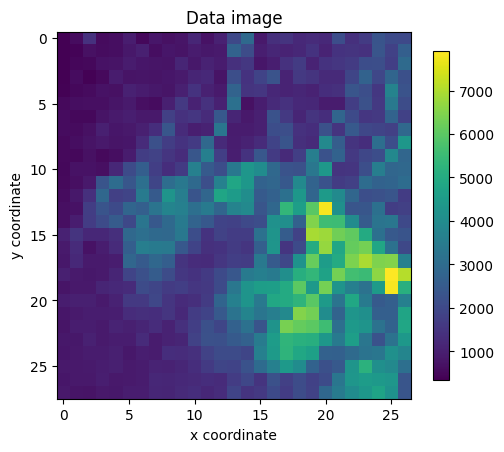

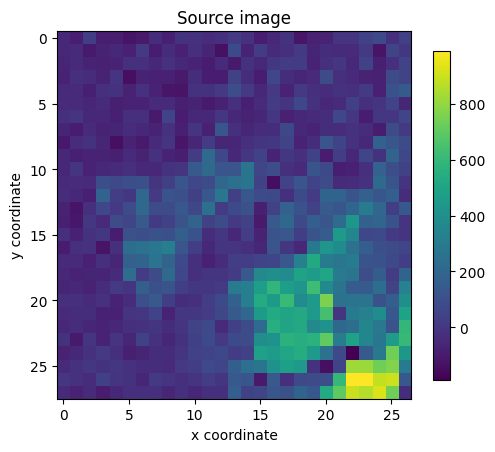

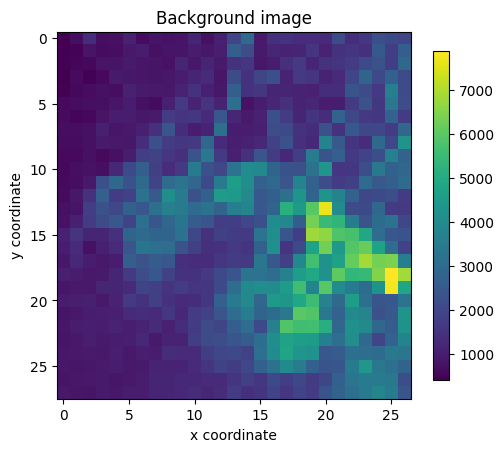

eigenvalues.shape = (756,)
eigenvectors.shape = (756, 756)


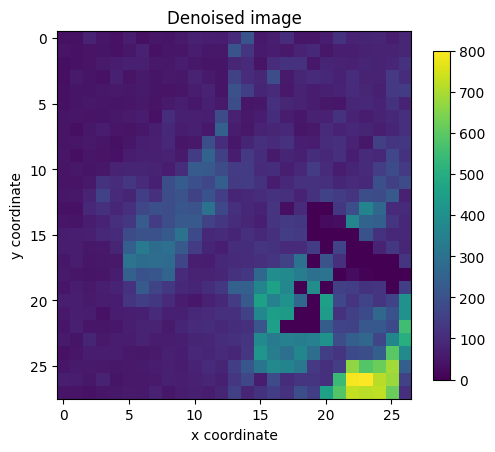

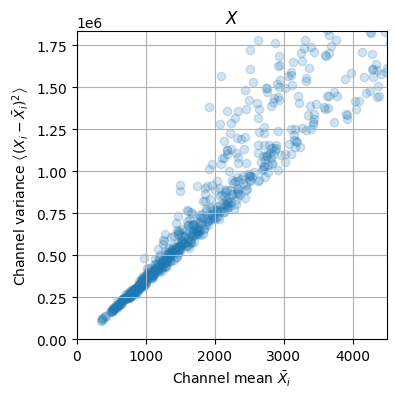

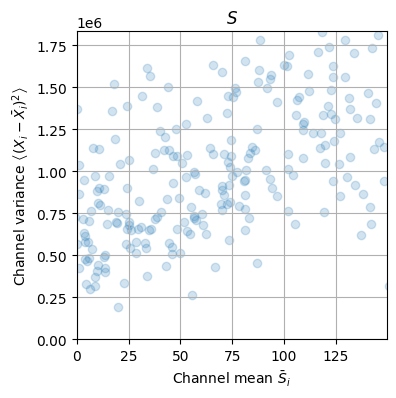

X.shape = (756, 2000)
X_mean.shape = (756, 2000)
GMP: X.shape = (756, 2000)
GMP: N.shape = (756, 2000)
GMP: best_sigma_scale = 0.95
len(nonzero_rho) = 45
mask = [False  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True False False False False
  True  True False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False]


/Users/rshang/miniforge3/envs/jax-arm/lib/python3.11/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/rshang/miniforge3/envs/jax-arm/lib/python3.11/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


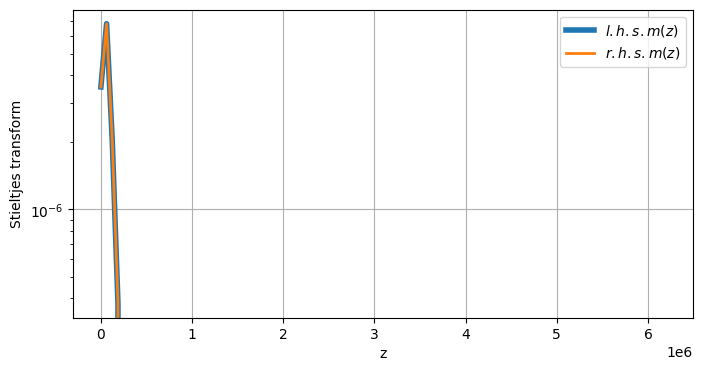

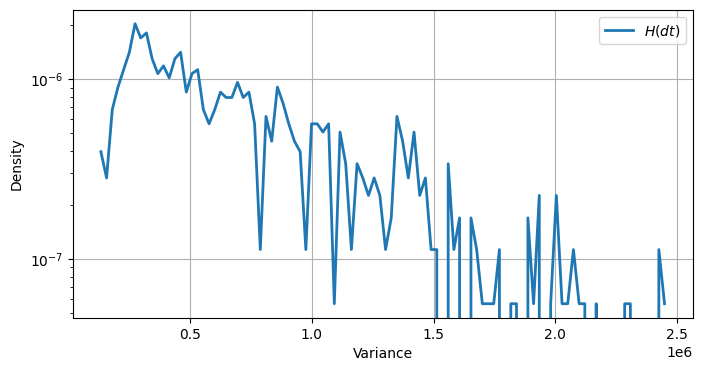

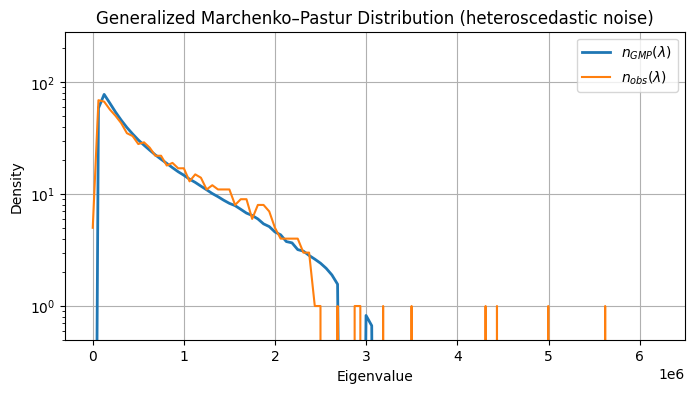

lambda_max_bulk_fit = 3059648.5
estimate_rank_signal = 13
eigenvalues.shape = (2000,)
eigenvectors.shape = (2000, 2000)
[[ 6.0849679e-03  3.3258896e-03  3.5297850e-03 ... -8.7277201e-04
  -4.1652303e-03 -2.5813221e-03]
 [ 3.3258896e-03  3.1611670e-03  1.9569790e-03 ... -7.2681642e-04
  -3.7519508e-03 -2.0222017e-03]
 [ 3.5297850e-03  1.9569790e-03  4.9520340e-03 ... -2.8611769e-04
  -3.6373793e-03 -1.3096813e-03]
 ...
 [-8.7277201e-04 -7.2681642e-04 -2.8611769e-04 ...  4.6467609e-03
   9.6163451e-05  2.4227312e-04]
 [-4.1652303e-03 -3.7519508e-03 -3.6373793e-03 ...  9.6163451e-05
   1.0277653e-02  5.9510637e-03]
 [-2.5813221e-03 -2.0222017e-03 -1.3096813e-03 ...  2.4227312e-04
   5.9510637e-03  4.7551380e-03]]
[[ 2.6733920e-04  1.7258464e-04 -1.3777354e-05 ...  1.3878147e-04
   8.9032430e-05  3.5544060e-04]
 [ 1.7258464e-04  3.0339646e-04 -1.6077257e-04 ... -1.5566600e-04
   4.6026346e-04  5.0191756e-04]
 [-1.3777354e-05 -1.6077257e-04  1.2667187e-03 ...  6.6193647e-04
  -8.9094274e-06

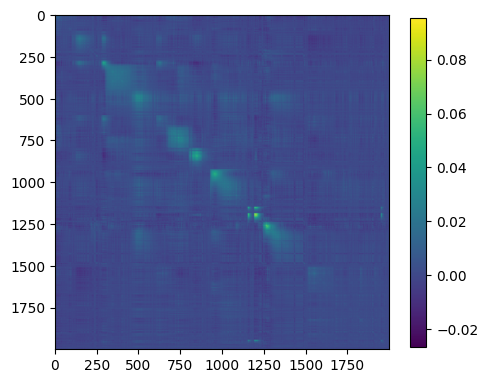

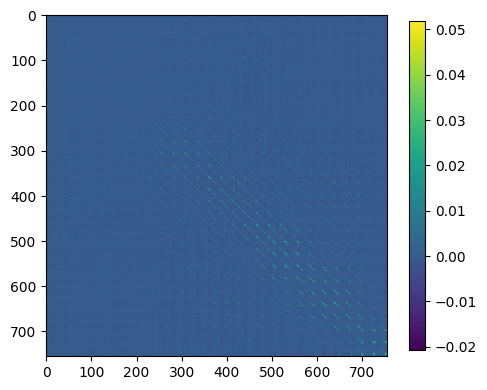

matching initial:


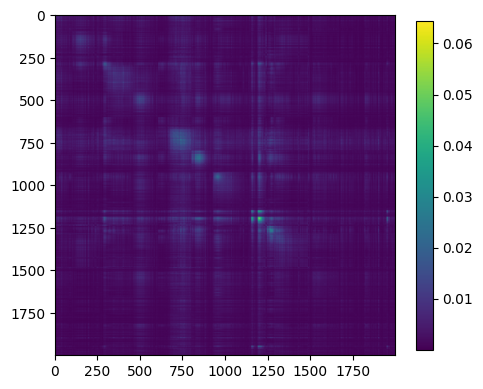

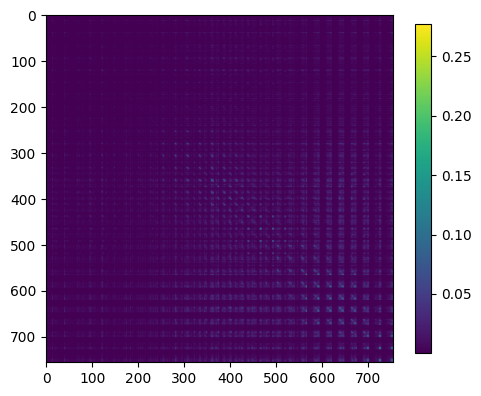

hybrid matching...


  0%|          | 0/5000 [00:00<?, ?it/s]

np.sum(np.abs(ZTZ)) = 13884.1064453125
np.sum(np.abs(HTH)) = 8035.12548828125
np.sum(np.abs(ZZT)) = 471.0118713378906
np.sum(np.abs(WWT)) = 101.1041030883789


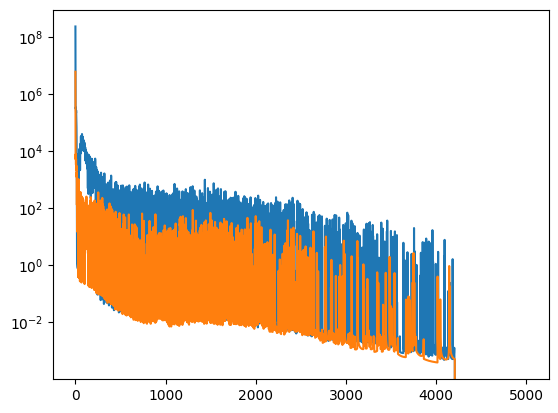

matching final:


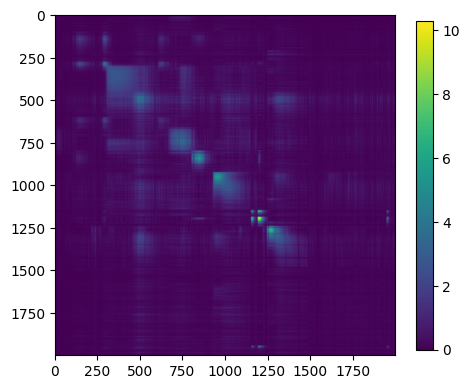

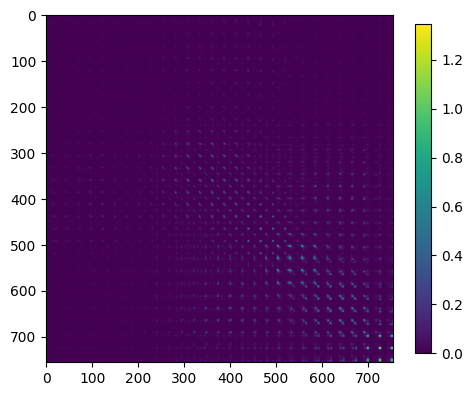

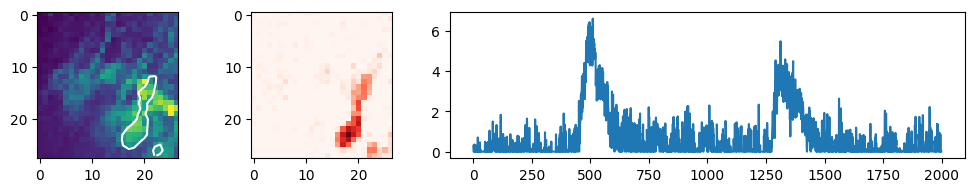

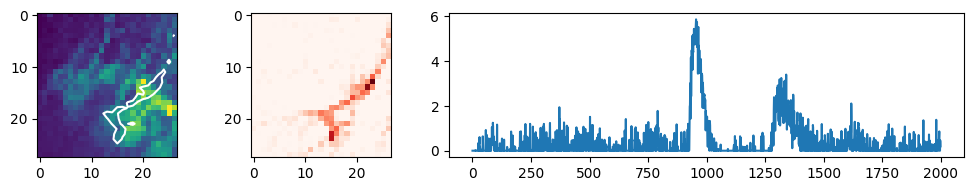

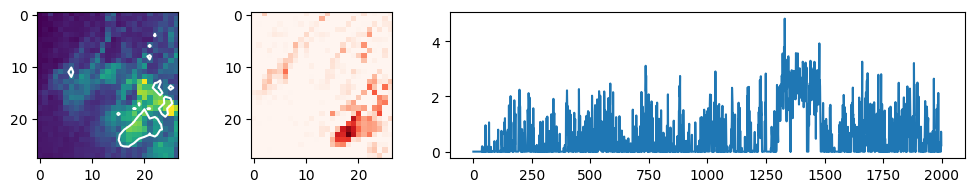

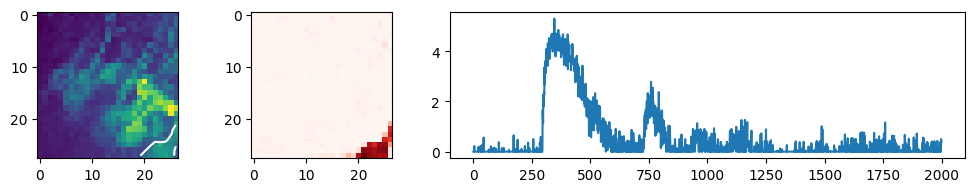

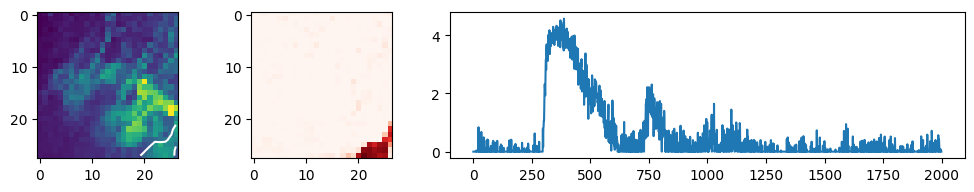

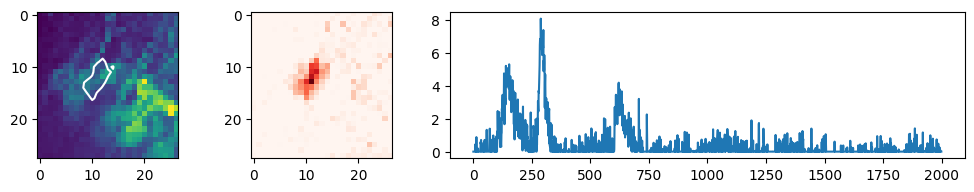

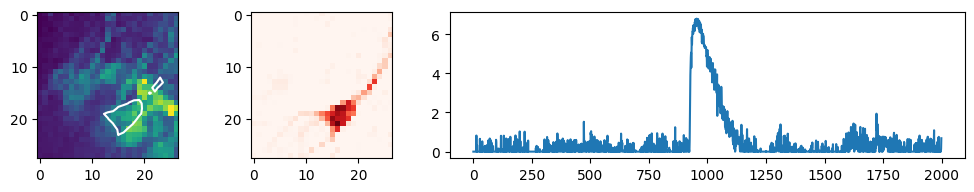

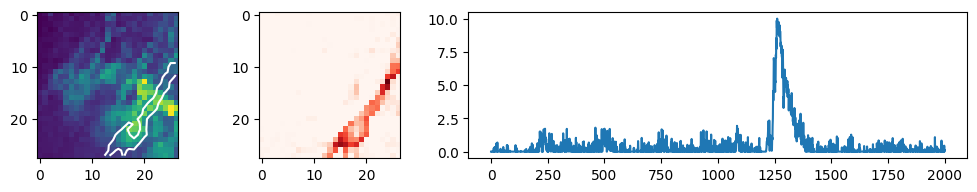

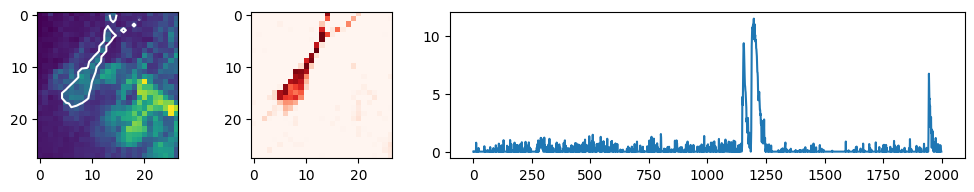

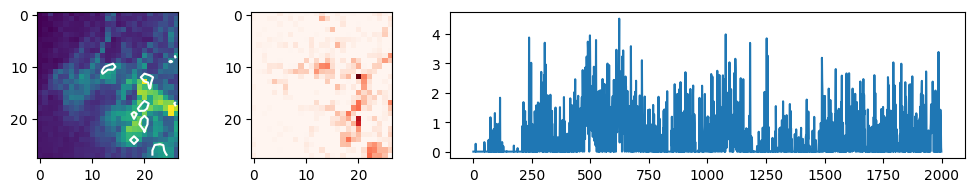

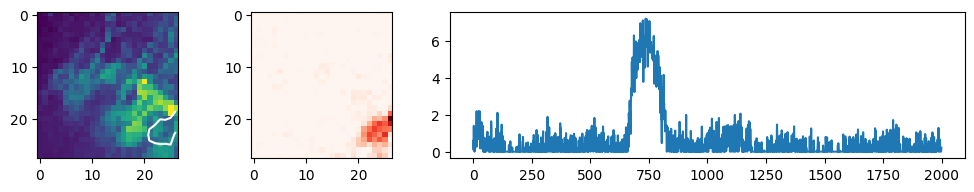

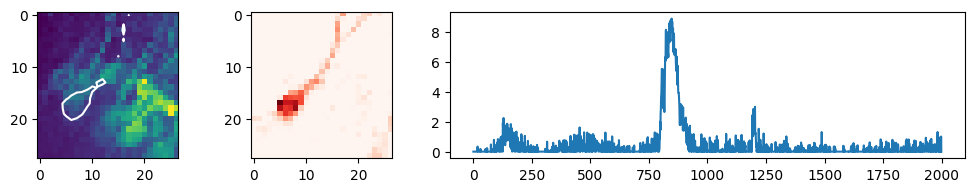

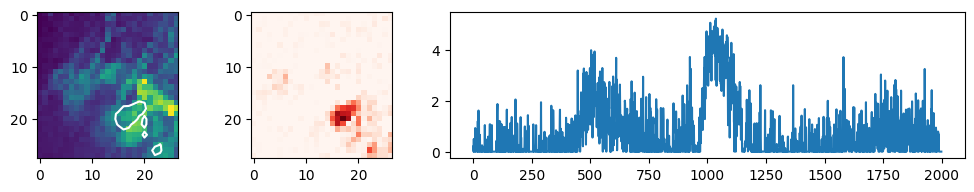

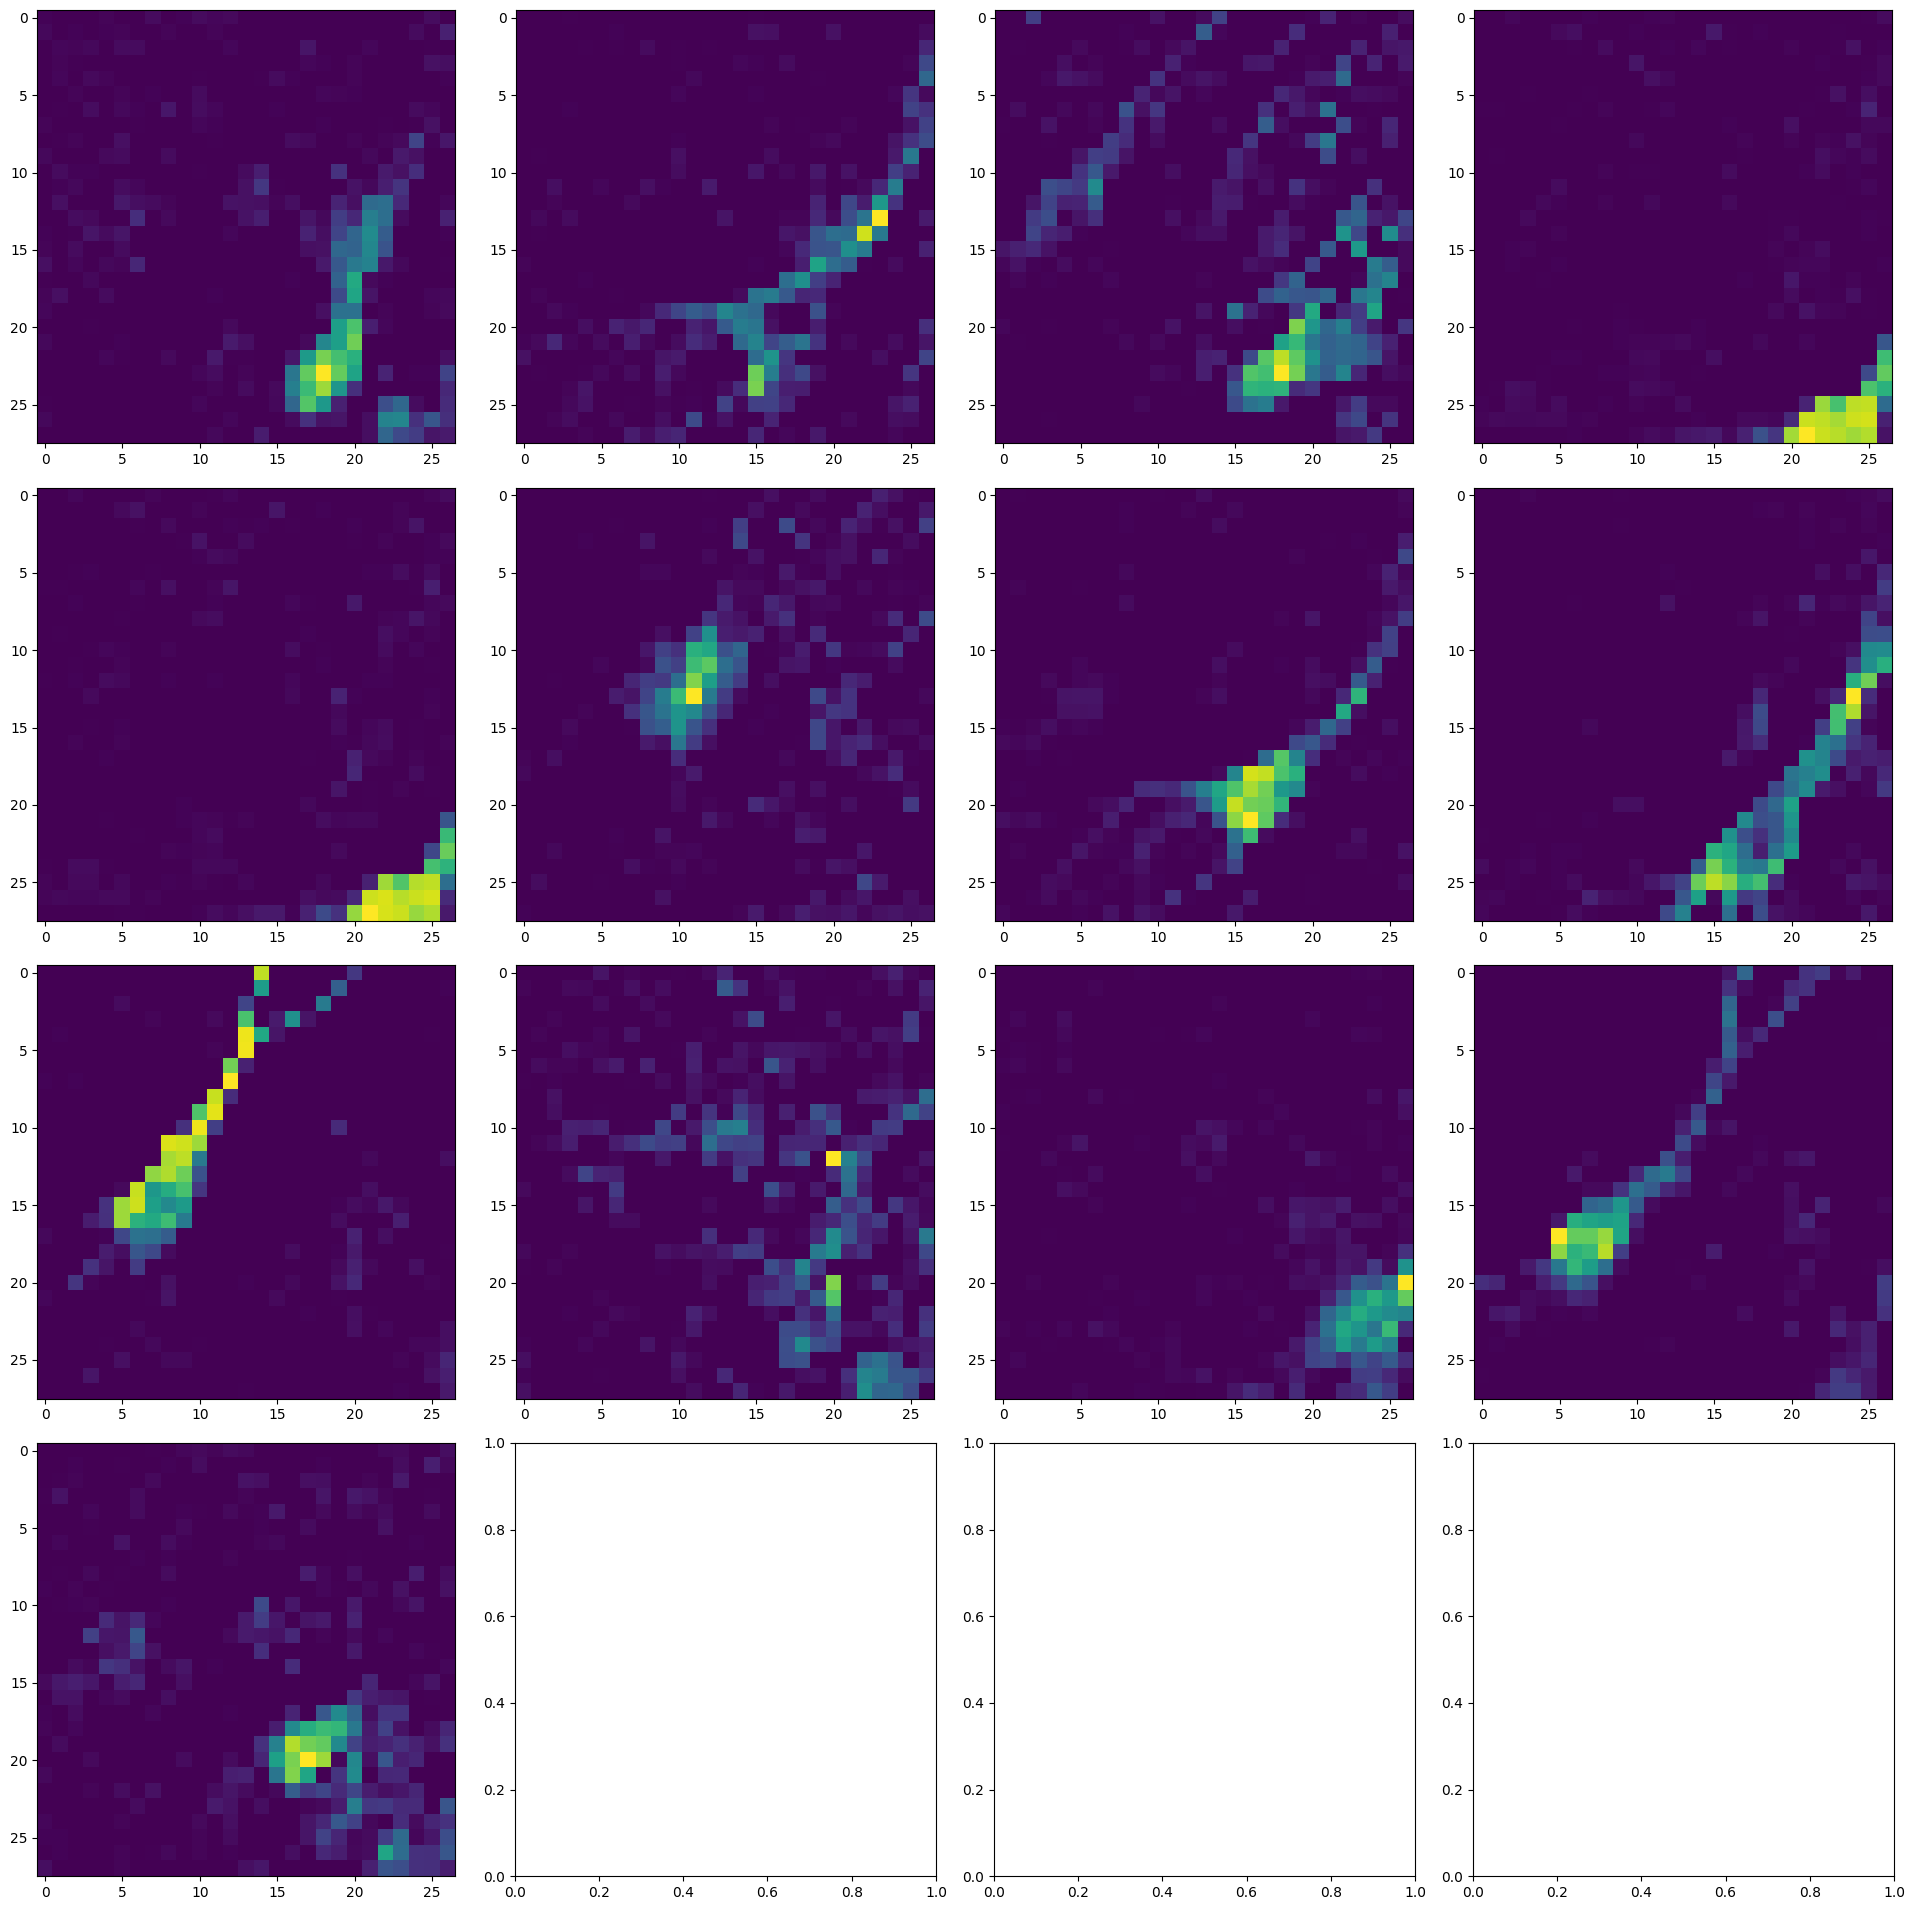

In [36]:
for fp, fl in zip(filepath,file_label):

    path = fp
    print (f"path = {path}")
    
    fig_label = fl + ana_label
    print (f"fig_label = {fig_label}")

    if "Calcium" in fig_label:
    
        movie, N_movie, pix_x_coord, pix_y_coord = read_data_file(path)
        vectorizer, unvec, X, Xn = vectorization(movie, N_movie)
        
        Cx, Cy = coordinate_vectorization(pix_x_coord, pix_y_coord)
        Xs, Xb = background_subtraction(X)
        Xc = centered_matrix(X, analysis_type)
        
        plot_image('data_image_'+fig_label, "Data image", unvec, X)
        plot_image('source_image_'+fig_label, "Source image", unvec, Xs)
        plot_image('background_image_'+fig_label, "Background image", unvec, Xb)

        noise_scaling(X, Xn)

        X_clean = denoising_image(Xs, Xn)
        plot_image('source_denoised_image_'+fig_label, "Denoised image", unvec, X_clean)

        channel_mean_vs_variance(X, Xs)

        # X_movie = fpl.ImageWidget(unvec.transform(X), figure_kwargs={"size": (500, 600)})
        # X_movie.show()

        matching_type = 0
        P, Pb, Pn, Ps, Pc = make_lag_time_data(X, Xb, Xs, Xn, matching_type)
        Px, Py = make_lag_time_coordinate(Cx, Cy)
        Z0 = make_concatenated_matrix(P)
        Zn0 = make_concatenated_matrix(Pn)
        Zs0 = make_concatenated_matrix(Ps)
        Zx = make_concatenated_matrix(Px)
        Zy = make_concatenated_matrix(Py)

        estimate_rank_signal = generalized_mp_density_fit(Xs, Xn, 100)

        if analysis_type==0 or analysis_type==1:

            matching_type = analysis_type
            Pw, Pcw, Pnw = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
            Zc = make_concatenated_matrix(Pcw)
            Zn = make_concatenated_matrix(Pnw)
            H0, W0 = nonnegative_similarity_matching(fig_label, Zc, estimate_rank_signal, matching_type)
            H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc, Zn, H0, W0, X.shape[0], estimate_rank_signal, matching_type)
            plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, estimate_rank_signal)
            plot_footprint_summary(fig_label, image_array, estimate_rank_signal)

        else:

            matching_type = 0
            Pw_sim, Pcw_sim, Pnw_sim = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
            Zc_sim = make_concatenated_matrix(Pcw_sim)
            Zn_sim = make_concatenated_matrix(Pnw_sim)
            matching_type = 1
            Pw_cov, Pcw_cov, Pnw_cov = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
            Zc_cov = make_concatenated_matrix(Pcw_cov)
            Zn_cov = make_concatenated_matrix(Pnw_cov)
            matching_type = 2
            H, W = nonnegative_hybrid_matching(fig_label, Zs0, Zc_sim, Zc_cov, estimate_rank_signal)
            H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc_cov, Zn_cov, H, W, X.shape[0], estimate_rank_signal, matching_type)
            plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, estimate_rank_signal)
            plot_footprint_summary(fig_label, image_array, estimate_rank_signal)
        

        # Zr = plot_residual(unvec, Zs0, H, W)

        

In [37]:
NICA_results = []
for fp, fl in zip(filepath,file_label):

    path = fp
    print (f"path = {path}")
    
    fig_label = fl + ana_label
    print (f"fig_label = {fig_label}")

    if "Fermi" in path:
        movie, N_movie, pix_x_coord, pix_y_coord, sky_x_coord, sky_y_coord, time_intervals, mjd_intervals = read_fermi_data_file(path)
        plot_image_from_movie(fig_label, movie)
        vectorizer, unvec, X, Xn = vectorization(movie, N_movie)
        
        Cx, Cy = coordinate_vectorization(pix_x_coord, pix_y_coord)
        Xs, Xb = background_subtraction(X)
        plot_image('source_image'+fig_label, "Source image", unvec, Xs)

        noise_scaling(X, Xn)

        matching_type = 0
        P, Pb, Pn, Ps, Pc = make_lag_time_data(X, Xb, Xs, Xn, matching_type)
        Px, Py = make_lag_time_coordinate(Cx, Cy)
        Z0 = make_concatenated_matrix(P)
        Zn0 = make_concatenated_matrix(Pn)
        Zs0 = make_concatenated_matrix(Ps)
        Zx = make_concatenated_matrix(Px)
        Zy = make_concatenated_matrix(Py)
        
        estimate_rank_signal = signal_rank_estimate(fig_label, Z0, Zn0, Zx, Zy)

        if analysis_type==0 or analysis_type==1:

            matching_type = analysis_type
            Pw, Pcw, Pnw = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
            Zc = make_concatenated_matrix(Pcw)
            Zn = make_concatenated_matrix(Pnw)
            H0, W0 = nonnegative_similarity_matching(fig_label, Zc, estimate_rank_signal, matching_type)
            H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc, Zn, H0, W0, X.shape[0], estimate_rank_signal, matching_type)
            plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, estimate_rank_signal)
            plot_footprint_summary(fig_label, image_array, estimate_rank_signal)

            NICA_results += [[fig_label, unvec, time_intervals, mjd_intervals, sky_x_coord, sky_y_coord, X, Z0, Zs0, Zn0, Zc, Zn, H, W, estimate_rank_signal]]

        else:

            matching_type = 0
            Pw_sim, Pcw_sim, Pnw_sim = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
            Zc_sim = make_concatenated_matrix(Pcw_sim)
            Zn_sim = make_concatenated_matrix(Pnw_sim)
            matching_type = 1
            Pw_cov, Pcw_cov, Pnw_cov = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal, matching_type)
            Zc_cov = make_concatenated_matrix(Pcw_cov)
            Zn_cov = make_concatenated_matrix(Pnw_cov)
            matching_type = 2
            H, W = nonnegative_hybrid_matching(fig_label, Zs0, Zc_sim, Zc_cov, estimate_rank_signal)
            H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc_cov, Zn_cov, H, W, X.shape[0], estimate_rank_signal, matching_type)
            plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, estimate_rank_signal)
            plot_footprint_summary(fig_label, image_array, estimate_rank_signal)

            NICA_results += [[fig_label, unvec, time_intervals, mjd_intervals, sky_x_coord, sky_y_coord, X, Z0, Zs0, Zn0, Zc_cov, Zn_cov, H, W, estimate_rank_signal]]
        
        

path = /Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif
fig_label = Calcium_filtercentered_hybrid_whiten_truncated_0lag


In [38]:
# for nr in range(0,len(NICA_results)):
for nr in range(0,1):

    if "Fermi" in path:
        print (f"len(NICA_results[nr]) = {len(NICA_results[nr])}")

        fig_label = NICA_results[nr][0]
        unvec = NICA_results[nr][1]
        time_intervals = NICA_results[nr][2]
        mjd_intervals = NICA_results[nr][3]
        sky_x_coord = NICA_results[nr][4]
        sky_y_coord = NICA_results[nr][5]
        X = NICA_results[nr][6]
        Z0 = NICA_results[nr][7]
        Zs0 = NICA_results[nr][8]
        Zn0 = NICA_results[nr][9]
        Zc = NICA_results[nr][10]
        Zn = NICA_results[nr][11]
        H = NICA_results[nr][12]
        W = NICA_results[nr][13]
        estimate_rank_signal = NICA_results[nr][14]

        print (f"np.sum(np.square(Z0)) = {np.sum(np.square(Z0))}")
        print (f"np.sum(np.square(Zn0)) = {np.sum(np.square(Zn0))}")

        matching_type = 1
        H, W, image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc, Zn, H, W, X.shape[0], estimate_rank_signal, matching_type)
        # plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, estimate_rank_signal, plot_noise=True)
        plot_footprint_summary(fig_label, image_array, estimate_rank_signal)
        plot_fermi_summary(fig_label, movie, sky_x_coord, sky_y_coord, image_array, estimate_rank_signal)

        src_variability_ts_cut = 25.
        src_variability_ts, src_fgl_varind = transient_detection(fig_label, unvec, time_intervals, mjd_intervals, sky_x_coord, sky_y_coord, X, Z0, image_array, S_solved, Sn_solved, src_variability_ts_cut, estimate_rank_signal)
        plot_fermi_variability_summary(fig_label, X, Z0, sky_x_coord, sky_y_coord, image_array, src_variability_ts, src_variability_ts_cut, estimate_rank_signal)